# EXP-VIT-YOLO-PIPELINE-034 — ViT (DeiT-Small, EXP-016) + YOLO26s (NEG_V04)

**Mục tiêu.** Kết hợp bộ phân loại toàn lá ViT của EXP-016 (5 seed) với bộ phát hiện vết bệnh YOLO26s đã huấn luyện trên dataset **NEG_V04** (có lá lạ bị bệnh làm ảnh nền), theo đúng khung kết hợp của EXP-033 (ResNet50 + YOLO), để:

1. So sánh **ViT một mình (F0)** với **ViT + YOLO (F3)** trên Validation sạch, Test và Holdout 09.
2. Đối chứng: **F3a** (cùng bộ học, bỏ YOLO) và **F3b** (chỉ YOLO) để biết mức tăng đến từ đâu.
3. Đo khả năng **từ chối lá lạ có vết bệnh** (126 + 76 ảnh `not_cashew_leaf_*` của NEG_V04 mà ViT chưa từng thấy) và ảnh tự chụp (ví dụ lá chuối) nếu bạn đặt `FIELD_TEST_DIR`.

**Không huấn luyện lại ViT hay YOLO.** Notebook chỉ đọc:
- Dự đoán 5 seed đã lưu của EXP-016 (`*_ANALYSIS.zip`, các file `predictions_standard.csv`).
- `best.pt` của `EXP-Y26S-NEG-V04-001` (SHA-256 được khóa).
- Ảnh của Split13, Holdout 09 và NEG_V04 để chạy YOLO và kiểm tra rò rỉ.
- `deployment_model.keras` (seed 7777) trong `*_FULL.zip` của EXP-016, chỉ cho phần đánh giá lá lạ.

**Quy tắc kết hợp (giữ như EXP-033):**

| Rule | Đầu vào bộ học | Ý nghĩa |
|---|---|---|
| F0 | — (argmax xác suất ViT) | ViT một mình |
| F3 | log-xác suất ViT (5 lớp) + 9 đặc trưng YOLO | ViT + YOLO (mặc định) |
| F3a | chỉ log-xác suất ViT | đối chứng: cùng bộ học, bỏ YOLO |
| F3b | chỉ 9 đặc trưng YOLO | đối chứng: YOLO một mình |

Đặc trưng YOLO cho mỗi lớp bệnh (ở `BOX_CONF`): confidence lớn nhất, `log1p(số box)`, tỉ lệ diện tích ảnh bị box phủ. Bộ học là hồi quy logistic đa lớp (chuẩn hóa + `C` chọn bằng 5-fold CV log-loss), **fit trên Validation sạch của từng seed**. Chỉ số Validation báo bằng dự đoán out-of-fold.

**Cổng lá lạ:** nhãn cuối là `not_cashew_leaf` thì kết luận "Không phải lá điều" và **ẩn mọi box YOLO**. Ngoài ra có ngưỡng "chưa chắc" (xác suất cao nhất thấp) chọn trên Validation sạch để giữ 95% ảnh.

**Giới hạn cần ghi trong khóa luận:** Holdout 09 đã được xem nhiều lần, chỉ là đánh giá mô tả. `BOX_CONF = 0.25` lấy theo EXP-033. Validation của bộ phân loại có thể trùng gần với ảnh train của YOLO; các ảnh đó bị loại khỏi "Validation sạch" (mục kiểm tra rò rỉ).


In [1]:
# 1. Cài đặt và import
import importlib.util, subprocess, sys

def ensure_package(pip_name, module_name):
    if importlib.util.find_spec(module_name) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name])

for pip_name, module_name in [('ultralytics==8.4.202', 'ultralytics'),
                              ('google-api-python-client', 'googleapiclient'),
                              ('google-auth', 'google.auth')]:
    ensure_package(pip_name, module_name)

import hashlib, io, json, math, os, platform, shutil, time, zipfile
from collections import Counter, defaultdict
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import ultralytics
from PIL import Image, ImageDraw, ImageOps
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, log_loss
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from ultralytics import YOLO

try:
    from IPython.display import display
except ImportError:  # chạy ngoài notebook
    display = print

plt.rcParams.update({'text.color': 'black', 'axes.labelcolor': 'black', 'axes.titlecolor': 'black',
                     'xtick.color': 'black', 'ytick.color': 'black'})
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
ENVIRONMENT = {'python': sys.version.split()[0], 'platform': platform.platform(), 'torch': torch.__version__,
               'ultralytics': ultralytics.__version__, 'sklearn': sklearn.__version__,
               'cuda': torch.cuda.is_available(),
               'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}
print(ENVIRONMENT)


{'python': '3.13.16', 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'torch': '2.11.0+cu130', 'ultralytics': '8.4.202', 'sklearn': '1.6.1', 'cuda': True, 'gpu': 'NVIDIA RTX PRO 6000 Blackwell Server Edition'}


In [2]:
# 2. CONFIG — mọi lựa chọn của thí nghiệm nằm ở đây
EXPERIMENT_ID = 'EXP-VIT-YOLO-PIPELINE-034'

# Bộ phân loại ViT EXP-016 (5 seed, đã khóa bằng Validation)
CLASSIFIER_EXPERIMENT_ID = 'EXP-VIT-DEITSMALL-TRANSFER-LLRD-5SEEDS-016-256px-1192fd08'
CLASSIFIER_DRIVE_FOLDER_ID = '1DGKTnzsvVc60RIEn5lQgflR3s-loM24G'
CLASSIFIER_ANALYSIS_ZIP_NAME = f'{CLASSIFIER_EXPERIMENT_ID}_ANALYSIS.zip'
CLASSIFIER_FULL_ZIP_NAME = f'{CLASSIFIER_EXPERIMENT_ID}_FULL.zip'  # chỉ cần cho đánh giá lá lạ
CLASSIFIER_ANALYSIS_ZIP_OVERRIDE = None   # đường dẫn local nếu đã có sẵn
CLASSIFIER_FULL_ZIP_OVERRIDE = None
CLASSIFIER_IMG_SIZE = 256

# Dataset phân loại Split13 và Holdout 09 (như EXP-016/033)
SPLIT13_NAME = 'CashewData_Split (13).zip'
SPLIT13_FILE_ID = '1HUE5ObO1vW0mP2QjgsdObMuW4RVPzNk7'
SPLIT13_BYTES = 1470301553
SPLIT13_SHA256 = 'e1647b72e10af04275dc760545f4ef17c9f44343ae119495b89ba1e3cd954e04'
SPLIT13_OVERRIDE = None
HOLDOUT_NAME = 'RL_Cashew_holdout (9).zip'
HOLDOUT_FILE_ID = '1QW2JYx8K6zkTs9y34f39OTBlxUOjWosZ'
HOLDOUT_BYTES = 370947341
HOLDOUT_OVERRIDE = None
KNOWN_HOLDOUT_DUPLICATES = ['real_healthy_40.jpg', 'real_healthy_42.jpg']  # chỉ số phụ n=124

# YOLO26s NEG_V04
YOLO_DATASET_NAME = 'CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip'
YOLO_DATASET_FOLDER_ID = '16S4O-7f7Tl2_xb0JrB5b-PJZA0FqKQ1M'
YOLO_DATASET_BYTES = 287009072
YOLO_DATASET_SHA256 = '4dca7b48a07fb971ef7f4e7c3b8cbe5b67f17bc411a7d43c060cece2e9e5798b'
YOLO_DATASET_OVERRIDE = None
YOLO_RUN_FULL_ZIP_NAME = 'EXP-Y26S-NEG-V04-001_FULL.zip'   # chứa train/weights/best.pt
YOLO_RUN_FOLDER_ID = None   # None: tìm theo tên trong toàn Drive
YOLO_WEIGHTS_SHA256 = 'f9dc3fba1347b3213819f61abddb36b07e455112d4e6e8d57eeeeca8ab1b7f4a'
YOLO_WEIGHTS_OVERRIDE = None   # đường dẫn best.pt nếu đã có

# Suy luận YOLO và đặc trưng
YOLO_IMGSZ = 640
YOLO_PROPOSAL_CONF = 0.05   # lưu mọi box từ mức này; đặc trưng dùng BOX_CONF
YOLO_NMS_IOU = 0.70
YOLO_MAX_DET = 300
BOX_CONF = 0.25             # theo EXP-033 (chọn trên YOLO Val); ghi rõ là kế thừa
DISPLAY_MAX_BOXES = 20

# Bộ kết hợp
SEEDS = [42, 123, 2026, 3407, 7777]
DEPLOYMENT_SEED = 7777
CLASS_NAMES = ['anthracnose', 'healthy', 'leaf_miner', 'red_rust', 'not_cashew_leaf']
DETECTOR_CLASSES = ['anthracnose', 'leaf_miner', 'red_rust']
DISEASE_CLASSES = ['anthracnose', 'leaf_miner', 'red_rust']
STACKER_C_GRID = [0.1, 0.3, 1.0, 3.0, 10.0]
CV_FOLDS = 5
RANDOM_STATE = 42
UNCERTAIN_COVERAGE = 0.95   # ngưỡng "chưa chắc": giữ 95% ảnh Validation sạch (OOF)
DEFAULT_RULE = 'F3'         # khai báo trước, không đổi sau khi xem Test/Holdout

# Kiểm tra rò rỉ (ảnh gần trùng)
NEAR_DUP_HAMMING = 4        # dHash 64 bit

# Đánh giá lá lạ (cần TensorFlow/KerasHub và deployment_model.keras)
RUN_FOREIGN_LEAF_EVAL = True
FIELD_TEST_DIR = None       # thư mục ảnh tự chụp (vd lá chuối có rỉ sắt) để thử đầu-cuối
LOADER_CHECK_IMAGES = 24    # số ảnh Validation dùng để so mô hình nạp lại với dự đoán đã lưu
LOADER_MAX_ABS_DIFF = 2e-3

BOOTSTRAP_REPS = 2000
UPLOAD_TO_DRIVE = True
DRIVE_RESULTS_FOLDER_ID = '1DGKTnzsvVc60RIEn5lQgflR3s-loM24G'  # tạo thư mục con EXPERIMENT_ID ở đây

WORK_ROOT = Path('/content/exp034' if Path('/content').exists() else Path.cwd() / 'exp034')


In [3]:
# 3. Thư mục làm việc, hàm tiện ích và Google Drive
OUT_DIR = WORK_ROOT / EXPERIMENT_ID
CACHE_DIR = WORK_ROOT / 'cache'
for directory in (OUT_DIR, CACHE_DIR, OUT_DIR / 'aggregate', OUT_DIR / 'figures', OUT_DIR / 'predictions',
                  OUT_DIR / 'pipeline_bundle'):
    directory.mkdir(parents=True, exist_ok=True)
AGG = OUT_DIR / 'aggregate'
FIG = OUT_DIR / 'figures'
PRED = OUT_DIR / 'predictions'
BUNDLE = OUT_DIR / 'pipeline_bundle'
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, default=str), encoding='utf-8')

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 << 20), b''):
            digest.update(block)
    return digest.hexdigest()

def md5_file(path):
    digest = hashlib.md5()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 << 20), b''):
            digest.update(block)
    return digest.hexdigest()

_DRIVE = {}
def drive_service():
    if 'service' in _DRIVE:
        return _DRIVE['service']
    import google.auth
    from googleapiclient.discovery import build
    try:
        from google.colab import auth
        auth.authenticate_user()
    except ImportError:
        pass
    credentials, _ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive'])
    _DRIVE['service'] = build('drive', 'v3', credentials=credentials, cache_discovery=False)
    return _DRIVE['service']

def find_drive_file(name, folder_id=None):
    service = drive_service()
    fields = 'files(id,name,size,md5Checksum,parents,modifiedTime)'
    queries = []
    if folder_id:
        queries.append(f"name = '{name}' and '{folder_id}' in parents and trashed = false")
    queries.append(f"name = '{name}' and trashed = false")
    for query in queries:
        found = service.files().list(q=query, fields=fields, supportsAllDrives=True,
                                     includeItemsFromAllDrives=True, corpora='allDrives',
                                     pageSize=50).execute().get('files', [])
        if len(found) == 1:
            return found[0]
        if len(found) > 1:
            raise RuntimeError(f'Nhiều file Drive tên {name}; đặt *_OVERRIDE hoặc ID cụ thể: {found}')
    raise FileNotFoundError(f'Không tìm thấy trên Drive: {name}')

def download_drive_file(meta, destination):
    from googleapiclient.http import MediaIoBaseDownload
    destination = Path(destination)
    if destination.is_file() and destination.stat().st_size == int(meta['size']):
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    partial = destination.with_suffix(destination.suffix + '.part')
    request = drive_service().files().get_media(fileId=meta['id'], supportsAllDrives=True)
    with partial.open('wb') as stream:
        downloader = MediaIoBaseDownload(stream, request, chunksize=32 << 20)
        done, last = False, -1
        while not done:
            progress, done = downloader.next_chunk(num_retries=5)
            if progress and int(progress.progress() * 10) != last:
                last = int(progress.progress() * 10)
                print(f"  {meta['name']}: {progress.progress():.0%}")
    if partial.stat().st_size != int(meta['size']):
        raise RuntimeError(f"Tải thiếu dữ liệu: {meta['name']}")
    if meta.get('md5Checksum') and md5_file(partial) != meta['md5Checksum']:
        raise RuntimeError(f"Sai MD5 khi tải: {meta['name']}")
    partial.replace(destination)
    return destination

def resolve_input(name, override=None, file_id=None, folder_id=None, expected_bytes=None, expected_sha256=None):
    """Trả về file local đã xác minh: override -> cache -> Drive (ID hoặc tìm theo tên)."""
    if override:
        path = Path(override).expanduser()
        if not path.is_file():
            raise FileNotFoundError(path)
    else:
        path = CACHE_DIR / name
        if not (path.is_file() and (expected_bytes is None or path.stat().st_size == expected_bytes)):
            if file_id:
                meta = drive_service().files().get(fileId=file_id, fields='id,name,size,md5Checksum',
                                                   supportsAllDrives=True).execute()
                if meta['name'] != name:
                    raise RuntimeError(f'Drive ID {file_id} là {meta["name"]}, cần {name}')
            else:
                meta = find_drive_file(name, folder_id)
            print('Tải', name, f"({int(meta['size']) / 1e6:.0f} MB)")
            download_drive_file(meta, path)
    if expected_bytes is not None and path.stat().st_size != expected_bytes:
        raise RuntimeError(f'{path.name}: {path.stat().st_size} byte, cần {expected_bytes}')
    digest = sha256_file(path)
    if expected_sha256 and digest != expected_sha256:
        raise RuntimeError(f'{path.name}: SHA-256 {digest}, cần {expected_sha256}')
    return path, digest

def safe_extract(archive, target, marker_value):
    target = Path(target)
    marker = target / '.extracted_from'
    if marker.is_file() and marker.read_text().strip() == marker_value:
        return target
    if target.exists():
        shutil.rmtree(target)
    target.mkdir(parents=True)
    with zipfile.ZipFile(archive) as z:
        root = target.resolve()
        for info in z.infolist():
            destination = (target / info.filename).resolve()
            if destination != root and root not in destination.parents:
                raise ValueError(f'Đường dẫn ZIP không an toàn: {info.filename}')
        z.extractall(target)
    marker.write_text(marker_value)
    return target

INPUTS = {}
print('Output:', OUT_DIR)


Output: /content/exp034/EXP-VIT-YOLO-PIPELINE-034


In [4]:
# 4. Tải và xác minh đầu vào
classifier_zip, digest = resolve_input(CLASSIFIER_ANALYSIS_ZIP_NAME, CLASSIFIER_ANALYSIS_ZIP_OVERRIDE,
                                       folder_id=CLASSIFIER_DRIVE_FOLDER_ID)
INPUTS['classifier_analysis_zip'] = {'name': classifier_zip.name, 'sha256': digest}

split13_zip, digest = resolve_input(SPLIT13_NAME, SPLIT13_OVERRIDE, file_id=SPLIT13_FILE_ID,
                                    expected_bytes=None if SPLIT13_OVERRIDE else SPLIT13_BYTES,
                                    expected_sha256=SPLIT13_SHA256)
INPUTS['split13_zip'] = {'name': split13_zip.name, 'sha256': digest}

holdout_zip, digest = resolve_input(HOLDOUT_NAME, HOLDOUT_OVERRIDE, file_id=HOLDOUT_FILE_ID,
                                    expected_bytes=None if HOLDOUT_OVERRIDE else HOLDOUT_BYTES)
INPUTS['holdout_zip'] = {'name': holdout_zip.name, 'sha256': digest}

yolo_zip, digest = resolve_input(YOLO_DATASET_NAME, YOLO_DATASET_OVERRIDE, folder_id=YOLO_DATASET_FOLDER_ID,
                                 expected_bytes=None if YOLO_DATASET_OVERRIDE else YOLO_DATASET_BYTES,
                                 expected_sha256=None if YOLO_DATASET_OVERRIDE else YOLO_DATASET_SHA256)
INPUTS['yolo_dataset_zip'] = {'name': yolo_zip.name, 'sha256': digest}

if YOLO_WEIGHTS_OVERRIDE:
    YOLO_WEIGHTS = Path(YOLO_WEIGHTS_OVERRIDE)
else:
    yolo_run_zip, _ = resolve_input(YOLO_RUN_FULL_ZIP_NAME, folder_id=YOLO_RUN_FOLDER_ID)
    YOLO_WEIGHTS = CACHE_DIR / 'yolo_neg_v04_best.pt'
    with zipfile.ZipFile(yolo_run_zip) as z:
        member = [n for n in z.namelist() if n.endswith('train/weights/best.pt')]
        if len(member) != 1:
            raise RuntimeError(f'{yolo_run_zip.name}: cần đúng 1 train/weights/best.pt, thấy {member}')
        YOLO_WEIGHTS.write_bytes(z.read(member[0]))
weights_sha = sha256_file(YOLO_WEIGHTS)
if weights_sha != YOLO_WEIGHTS_SHA256:
    raise RuntimeError(f'best.pt SHA-256 {weights_sha}, cần {YOLO_WEIGHTS_SHA256}')
INPUTS['yolo_weights'] = {'name': 'EXP-Y26S-NEG-V04-001 best.pt', 'sha256': weights_sha}

def extract_root(archive, name, required):
    root = safe_extract(archive, CACHE_DIR / f'extract_{name}', INPUTS_KEY[name])
    candidates = [p for p in [root, *root.rglob('*')] if p.is_dir() and all((p / r).is_dir() for r in required)]
    if len(candidates) != 1:
        raise RuntimeError(f'{name}: cần đúng 1 thư mục chứa {required}, thấy {candidates[:5]}')
    return candidates[0]

INPUTS_KEY = {'split13': INPUTS['split13_zip']['sha256'], 'holdout': INPUTS['holdout_zip']['sha256'],
              'yolo': INPUTS['yolo_dataset_zip']['sha256']}
SPLIT13_ROOT = extract_root(split13_zip, 'split13', ['train', 'val', 'test'])
HOLDOUT_ROOT = extract_root(holdout_zip, 'holdout', ['anthracnose', 'healthy', 'leaf_miner', 'red_rust'])
YOLO_ROOT = extract_root(yolo_zip, 'yolo', ['images/train', 'images/val', 'images/test'])
print('Split13:', SPLIT13_ROOT, '\nHoldout:', HOLDOUT_ROOT, '\nYOLO NEG_V04:', YOLO_ROOT)
save_json(OUT_DIR / 'inputs.json', INPUTS)
display(pd.DataFrame(INPUTS).T)


Split13: /content/exp034/cache/extract_split13/CashewData_Split 
Holdout: /content/exp034/cache/extract_holdout/RL_Cashew_holdout 
YOLO NEG_V04: /content/exp034/cache/extract_yolo/CASHEW_YOLO_MASTER_FINAL_NEG_V04


,name,sha256
classifier_analysis_zip,EXP-VIT-DEITSMALL-TRANSFER-LLRD-5SEEDS-016-256...,ee321110aaf7095ae1d4a43cb3f04b77ebdbdad9436553...
split13_zip,CashewData_Split (13).zip,e1647b72e10af04275dc760545f4ef17c9f44343ae1194...
holdout_zip,RL_Cashew_holdout (9).zip,485512a7142e36df081b8439bcc0b6d2ae59873d1897e6...
yolo_dataset_zip,CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip,4dca7b48a07fb971ef7f4e7c3b8cbe5b67f17bc411a7d4...
yolo_weights,EXP-Y26S-NEG-V04-001 best.pt,f9dc3fba1347b3213819f61abddb36b07e455112d4e6e8...


In [5]:
# 5. Dự đoán 5 seed của ViT EXP-016 và ánh xạ sang file ảnh
PROB_COLS = [f'prob_{name}' for name in CLASS_NAMES]

with zipfile.ZipFile(classifier_zip) as z:
    names = z.namelist()
    lock_member = [n for n in names if n.endswith('validation_selection_lock.json')]
    if len(lock_member) != 1:
        raise RuntimeError(f'Không thấy validation_selection_lock.json duy nhất trong {classifier_zip.name}')
    PREFIX = lock_member[0][:-len('validation_selection_lock.json')]
    CLASSIFIER_LOCK = json.loads(z.read(lock_member[0]))
    if CLASSIFIER_LOCK.get('class_names', CLASS_NAMES) != CLASS_NAMES:
        raise RuntimeError(f"Thứ tự lớp khác: {CLASSIFIER_LOCK.get('class_names')}")
    frames = []
    for seed in SEEDS:
        for split, member in (('validation', f'{PREFIX}seed_{seed}/validation/predictions_standard.csv'),
                              ('test', f'{PREFIX}seed_{seed}/test/predictions_standard.csv'),
                              ('holdout', f'{PREFIX}real_holdout/seed_{seed}/predictions_standard.csv')):
            if member not in names:
                raise FileNotFoundError(f'{classifier_zip.name} thiếu {member}')
            frame = pd.read_csv(io.BytesIO(z.read(member)))
            missing = [c for c in PROB_COLS + ['image_id', 'true_label'] if c not in frame.columns]
            if missing:
                raise RuntimeError(f'{member} thiếu cột {missing}')
            if not np.allclose(frame[PROB_COLS].sum(axis=1), 1, atol=1e-4):
                raise RuntimeError(f'{member}: xác suất không cộng bằng 1')
            frame = frame[['image_id', 'true_label'] + PROB_COLS].copy()
            frame['seed'], frame['split'] = seed, split
            frames.append(frame)
CLS_PRED = pd.concat(frames, ignore_index=True)

# Ánh xạ khóa ảnh sang file thật
def index_by_class_and_name(root):
    index = {}
    for path in root.rglob('*'):
        if path.suffix.lower() in IMAGE_SUFFIXES:
            index.setdefault((path.parent.name, path.name), []).append(path)
    return index

holdout_index = index_by_class_and_name(HOLDOUT_ROOT)
def resolve_image(split, image_id):
    parts = image_id.split('/')
    if split == 'holdout':
        hits = holdout_index.get((parts[-2], parts[-1]), [])
        if len(hits) != 1:
            raise FileNotFoundError(f'Holdout: {image_id} -> {hits}')
        return hits[0]
    path = SPLIT13_ROOT / image_id
    if not path.is_file():
        raise FileNotFoundError(f'{split}: {image_id}')
    return path

key_frame = CLS_PRED.drop_duplicates(['split', 'image_id'])[['split', 'image_id', 'true_label']].copy()
key_frame['path'] = [str(resolve_image(s, i)) for s, i in zip(key_frame['split'], key_frame['image_id'])]
CLS_PRED = CLS_PRED.merge(key_frame[['split', 'image_id', 'path']], on=['split', 'image_id'], how='left')

# Mọi seed phải có cùng tập ảnh và cùng nhãn thật
check = CLS_PRED.groupby(['split', 'image_id'])['true_label'].agg(['nunique', 'size'])
if (check['nunique'] != 1).any() or (check['size'] != len(SEEDS)).any():
    raise RuntimeError('Các seed không cùng tập ảnh hoặc nhãn thật')
counts = key_frame.groupby(['split', 'true_label']).size().unstack(fill_value=0)
display(counts)
print('Ảnh theo tập:', key_frame['split'].value_counts().to_dict())


true_label,anthracnose,healthy,leaf_miner,not_cashew_leaf,red_rust
split,,,,,
holdout,46,19,36,0,25
test,120,118,130,156,161
validation,309,227,267,314,335


Ảnh theo tập: {'validation': 1452, 'test': 685, 'holdout': 126}


In [6]:
# 6. Kiểm tra rò rỉ: ảnh bộ phân loại trùng/gần trùng ảnh train của YOLO NEG_V04
def dhash64(path):
    with Image.open(path) as image:
        image.draft('L', (64, 64))
        pixels = np.asarray(image.convert('L').resize((9, 8)), dtype=np.int16)
    bits = (pixels[:, 1:] > pixels[:, :-1]).flatten()
    return int(sum(1 << i for i, b in enumerate(bits) if b))

yolo_train_images = sorted(p for p in (YOLO_ROOT / 'images' / 'train').iterdir() if p.suffix.lower() in IMAGE_SUFFIXES)
yolo_hash = {str(p): dhash64(p) for p in yolo_train_images}
yolo_sha = defaultdict(list)
for p in yolo_train_images:
    yolo_sha[sha256_file(p)].append(p.name)
bands = defaultdict(list)
for path, h in yolo_hash.items():
    for b in range(4):
        bands[(b, (h >> (16 * b)) & 0xFFFF)].append(path)

leak_rows = []
for row in key_frame.itertuples():
    h = dhash64(row.path)
    candidates = {p for b in range(4) for p in bands.get((b, (h >> (16 * b)) & 0xFFFF), [])}
    near = sorted((bin(h ^ yolo_hash[p]).count('1'), Path(p).name) for p in candidates)
    near = [(d, n) for d, n in near if d <= NEAR_DUP_HAMMING]
    exact = yolo_sha.get(sha256_file(row.path), [])
    leak_rows.append({'split': row.split, 'image_id': row.image_id, 'exact_yolo_train': ';'.join(exact),
                      'near_yolo_train': ';'.join(f'{n}:{d}' for d, n in near[:5]),
                      'leak': bool(exact or near)})
LEAK = pd.DataFrame(leak_rows)
LEAK.to_csv(AGG / 'leakage_vs_yolo_train.csv', index=False)
leak_summary = LEAK.groupby('split')['leak'].agg(['size', 'sum']).rename(columns={'size': 'images', 'sum': 'leaked'})
save_json(AGG / 'leakage_audit.json', {'near_dup_hamming': NEAR_DUP_HAMMING, 'yolo_train_images': len(yolo_train_images),
                                       'by_split': leak_summary.to_dict(orient='index')})
display(leak_summary)
LEAKED = set(zip(LEAK.loc[LEAK['leak'], 'split'], LEAK.loc[LEAK['leak'], 'image_id']))
print('Validation sạch = Validation trừ', sum(1 for s, _ in LEAKED if s == 'validation'), 'ảnh trùng/gần trùng ảnh train YOLO.')


,images,leaked
split,,
holdout,126,0
test,685,1
validation,1452,2


Validation sạch = Validation trừ 2 ảnh trùng/gần trùng ảnh train YOLO.


In [7]:
# 7. Chạy YOLO NEG_V04 một lần trên mọi ảnh, lưu toàn bộ box rồi tính đặc trưng
detector = YOLO(str(YOLO_WEIGHTS))
if [detector.names[i] for i in sorted(detector.names)] != DETECTOR_CLASSES:
    raise RuntimeError(f'Lớp YOLO khác mong đợi: {detector.names}')

def run_detector(paths, batch=32):
    rows, sizes = [], {}
    for start in range(0, len(paths), batch):
        chunk = paths[start:start + batch]
        results = detector.predict(chunk, imgsz=YOLO_IMGSZ, conf=YOLO_PROPOSAL_CONF, iou=YOLO_NMS_IOU,
                                   max_det=YOLO_MAX_DET, device=DEVICE, verbose=False)
        for path, result in zip(chunk, results):
            h, w = result.orig_shape
            sizes[path] = (w, h)
            boxes = result.boxes
            for cls, conf, xyxy in zip(boxes.cls.cpu().numpy(), boxes.conf.cpu().numpy(), boxes.xyxy.cpu().numpy()):
                rows.append({'path': path, 'cls': DETECTOR_CLASSES[int(cls)], 'conf': float(conf),
                             'x1': float(xyxy[0]) / w, 'y1': float(xyxy[1]) / h,
                             'x2': float(xyxy[2]) / w, 'y2': float(xyxy[3]) / h})
        print(f'  YOLO: {min(start + batch, len(paths))}/{len(paths)}', end='\r')
    print()
    return pd.DataFrame(rows, columns=['path', 'cls', 'conf', 'x1', 'y1', 'x2', 'y2']), sizes

def union_fraction(boxes, grid=128):
    if not len(boxes):
        return 0.0
    mask = np.zeros((grid, grid), dtype=bool)
    for x1, y1, x2, y2 in boxes:
        mask[int(np.floor(y1 * grid)):int(np.ceil(y2 * grid)), int(np.floor(x1 * grid)):int(np.ceil(x2 * grid))] = True
    return float(mask.mean())

YOLO_FEATURE_COLS = [f'{kind}_{name}' for name in DETECTOR_CLASSES for kind in ('max_conf', 'n_boxes', 'area_frac')]

def detector_features(paths, boxes):
    kept = boxes[boxes['conf'] >= BOX_CONF]
    grouped = {key: frame for key, frame in kept.groupby(['path', 'cls'])}
    rows = []
    for path in paths:
        row = {'path': path}
        for name in DETECTOR_CLASSES:
            frame = grouped.get((path, name))
            if frame is None:
                row.update({f'max_conf_{name}': 0.0, f'n_boxes_{name}': 0, f'area_frac_{name}': 0.0})
            else:
                row.update({f'max_conf_{name}': float(frame['conf'].max()), f'n_boxes_{name}': int(len(frame)),
                            f'area_frac_{name}': union_fraction(frame[['x1', 'y1', 'x2', 'y2']].to_numpy())})
        rows.append(row)
    return pd.DataFrame(rows)

started = time.perf_counter()
all_paths = key_frame['path'].tolist()
BOXES, IMAGE_SIZES = run_detector(all_paths)
YOLO_SECONDS = time.perf_counter() - started
BOXES.to_csv(PRED / 'detector_boxes_all.csv.gz', index=False, compression='gzip')
EVIDENCE = detector_features(all_paths, BOXES)
EVIDENCE.to_csv(AGG / 'detector_evidence.csv', index=False)
print(f'YOLO: {len(all_paths)} ảnh, {len(BOXES)} box ≥ {YOLO_PROPOSAL_CONF}, {YOLO_SECONDS:.0f} giây')
display(EVIDENCE.merge(key_frame, on='path').groupby(['split', 'true_label'])[[f'n_boxes_{c}' for c in DETECTOR_CLASSES]].mean().round(2))


  YOLO: 2263/2263
YOLO: 2263 ảnh, 168670 box ≥ 0.05, 17 giây


n_boxes_anthracnose  n_boxes_leaf_miner  \
split      true_label                                                 
holdout    anthracnose                    15.87                0.00   
           healthy                         0.21                0.05   
           leaf_miner                      2.39                2.64   
           red_rust                        6.36                0.04   
test       anthracnose                    16.58                0.02   
           healthy                         0.17                0.00   
           leaf_miner                      3.76                2.21   
           not_cashew_leaf                 1.67                0.00   
           red_rust                        3.73                0.00   
validation anthracnose                    40.61                0.03   
           healthy                         0.06                0.00   
           leaf_miner                      3.97                2.12   
           not_cashew_leaf                 0.24                0.03   
           red_rust                        3.53                0.00   

                            n_boxes_red_rust  
split      true_label                         
holdout    anthracnose                  0.76  
           healthy                      0.00  
           leaf_miner                   0.00  
           red_rust                    24.92  
test       anthracnose                  0.15  
           healthy                      0.00  
           leaf_miner                   1.43  
           not_cashew_leaf              0.02  
           red_rust                    85.01  
validation anthracnose                  0.11  
           healthy                      0.01  
           leaf_miner                   0.90  
           not_cashew_leaf              0.03  
           red_rust                    94.99

In [8]:
# 8. Bộ kết hợp F0 / F3 / F3a / F3b cho từng seed (fit trên Validation sạch)
RULES = {'F0': None,
         'F3': PROB_COLS + YOLO_FEATURE_COLS,
         'F3a': PROB_COLS,
         'F3b': YOLO_FEATURE_COLS}
LABEL_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}

def feature_matrix(frame, columns):
    parts = []
    for column in columns:
        values = frame[column].to_numpy(dtype=float)
        if column.startswith('prob_'):
            values = np.log(np.clip(values, 1e-6, 1.0))
        elif column.startswith('n_boxes_'):
            values = np.log1p(values)
        parts.append(values)
    return np.column_stack(parts)

def make_stacker(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))

def fit_stacker(X, y):
    folds = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    cv_rows = []
    for C in STACKER_C_GRID:
        oof = np.zeros((len(y), len(CLASS_NAMES)))
        for train_idx, test_idx in folds.split(X, y):
            model = make_stacker(C).fit(X[train_idx], y[train_idx])
            oof[np.ix_(test_idx, model.classes_)] = model.predict_proba(X[test_idx])
        oof = np.clip(oof, 1e-9, 1.0); oof /= oof.sum(axis=1, keepdims=True)
        cv_rows.append({'C': C, 'cv_log_loss': log_loss(y, oof, labels=range(len(CLASS_NAMES))), 'oof': oof})
    best = min(cv_rows, key=lambda r: (r['cv_log_loss'], -r['C']))
    model = make_stacker(best['C']).fit(X, y)
    return model, best['C'], best['oof'], [{'C': r['C'], 'cv_log_loss': r['cv_log_loss']} for r in cv_rows]

def predict_full(model, X):
    probabilities = np.zeros((len(X), len(CLASS_NAMES)))
    probabilities[:, model.classes_] = model.predict_proba(X)
    return probabilities

DATA = CLS_PRED.merge(EVIDENCE, on='path', how='left')
DATA['y'] = DATA['true_label'].map(LABEL_TO_INDEX)
DATA['clean'] = [(s, i) not in LEAKED for s, i in zip(DATA['split'], DATA['image_id'])]
DATA['n124'] = ~DATA['image_id'].str.split('/').str[-1].isin(KNOWN_HOLDOUT_DUPLICATES)

STACKERS, CV_TABLE, PREDICTIONS = {}, [], []
for seed in SEEDS:
    seed_data = DATA[DATA['seed'] == seed]
    train = seed_data[(seed_data['split'] == 'validation') & seed_data['clean']]
    y_train = train['y'].to_numpy()
    for rule, columns in RULES.items():
        out = seed_data[['split', 'image_id', 'path', 'true_label', 'y', 'clean', 'n124']].copy()
        out['seed'], out['rule'] = seed, rule
        if columns is None:
            probabilities = seed_data[PROB_COLS].to_numpy(dtype=float)
            out['oof'] = False
        else:
            model, C, oof, cv = fit_stacker(feature_matrix(train, columns), y_train)
            STACKERS[(seed, rule)] = {'model': model, 'C': C, 'columns': columns}
            CV_TABLE += [{'seed': seed, 'rule': rule, **row, 'selected': row['C'] == C} for row in cv]
            probabilities = predict_full(model, feature_matrix(seed_data, columns))
            # Validation sạch: thay bằng dự đoán out-of-fold để không đánh giá trên chính dữ liệu fit
            clean_val = ((seed_data['split'] == 'validation') & seed_data['clean']).to_numpy()
            probabilities[clean_val] = oof
            out['oof'] = clean_val
        for i, name in enumerate(CLASS_NAMES):
            out[f'p_{name}'] = probabilities[:, i]
        out['pred'] = [CLASS_NAMES[i] for i in probabilities.argmax(axis=1)]
        out['confidence'] = probabilities.max(axis=1)
        PREDICTIONS.append(out)
    print('seed', seed, 'C =', {r: STACKERS[(seed, r)]['C'] for r in RULES if RULES[r]})
PREDICTIONS = pd.concat(PREDICTIONS, ignore_index=True)
pd.DataFrame(CV_TABLE).to_csv(AGG / 'stacker_cv.csv', index=False)
PREDICTIONS.to_csv(PRED / 'fused_predictions_all.csv.gz', index=False, compression='gzip')


seed 42 C = {'F3': 1.0, 'F3a': 3.0, 'F3b': 1.0}
seed 123 C = {'F3': 1.0, 'F3a': 3.0, 'F3b': 1.0}
seed 2026 C = {'F3': 1.0, 'F3a': 3.0, 'F3b': 1.0}
seed 3407 C = {'F3': 1.0, 'F3a': 3.0, 'F3b': 1.0}
seed 7777 C = {'F3': 1.0, 'F3a': 3.0, 'F3b': 1.0}


In [9]:
# 9. Ngưỡng "chưa chắc" (chọn trên Validation sạch OOF, giữ UNCERTAIN_COVERAGE ảnh) và cổng lá lạ
UNCERTAIN_THRESHOLD = {}
for (seed, rule), frame in PREDICTIONS[(PREDICTIONS['split'] == 'validation') & PREDICTIONS['clean']].groupby(['seed', 'rule']):
    UNCERTAIN_THRESHOLD[(seed, rule)] = float(np.quantile(frame['confidence'], 1 - UNCERTAIN_COVERAGE))
PREDICTIONS['uncertain'] = [c < UNCERTAIN_THRESHOLD[(s, r)] for s, r, c in
                            zip(PREDICTIONS['seed'], PREDICTIONS['rule'], PREDICTIONS['confidence'])]

def final_decision(pred, uncertain):
    if pred == 'not_cashew_leaf':
        return 'rejected_not_cashew'
    if uncertain:
        return 'uncertain_retake'
    return pred
PREDICTIONS['decision'] = [final_decision(p, u) for p, u in zip(PREDICTIONS['pred'], PREDICTIONS['uncertain'])]
save_json(AGG / 'uncertain_thresholds.json', {f'{s}|{r}': t for (s, r), t in UNCERTAIN_THRESHOLD.items()})
print('Ngưỡng chưa chắc (seed triển khai):', {r: round(UNCERTAIN_THRESHOLD[(DEPLOYMENT_SEED, r)], 3) for r in RULES})


Ngưỡng chưa chắc (seed triển khai): {'F0': 0.909, 'F3': 0.938, 'F3a': 0.902, 'F3b': 0.56}


In [10]:
# 10. Chỉ số theo seed, rule và tập; trung bình ± độ lệch chuẩn 5 seed
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - h) / d, (c + h) / d)

def ece15(frame):
    confidence = frame['confidence'].to_numpy(); correct = (frame['pred'] == frame['true_label']).to_numpy()
    bins = np.linspace(0, 1, 16); total = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (confidence > lo) & (confidence <= hi)
        if mask.any():
            total += mask.mean() * abs(correct[mask].mean() - confidence[mask].mean())
    return total

EVAL_SETS = {
    'validation_clean_oof': lambda f: f[(f['split'] == 'validation') & f['clean']],
    'test': lambda f: f[f['split'] == 'test'],
    'test_clean': lambda f: f[(f['split'] == 'test') & f['clean']],
    'holdout': lambda f: f[f['split'] == 'holdout'],
    'holdout_n124': lambda f: f[(f['split'] == 'holdout') & f['n124']],
}

def metrics(frame):
    truth, pred = frame['true_label'], frame['pred']
    n, k = len(frame), int((truth == pred).sum())
    present = [c for c in CLASS_NAMES if (truth == c).any()]
    disease = truth.isin(DISEASE_CLASSES)
    row = {'n': n, 'correct': k, 'accuracy': k / n, 'wilson_low': wilson(k, n)[0], 'wilson_high': wilson(k, n)[1],
           'macro_f1': f1_score(truth, pred, labels=present, average='macro', zero_division=0),
           'ece15': ece15(frame),
           'missed_disease': int((disease & pred.isin(['healthy', 'not_cashew_leaf'])).sum()),
           'false_alarm_healthy': int(((truth == 'healthy') & pred.isin(DISEASE_CLASSES)).sum()),
           'cashew_rejected': int(((truth != 'not_cashew_leaf') & (pred == 'not_cashew_leaf')).sum()),
           'uncertain_share': float(frame['uncertain'].mean()),
           'accuracy_when_certain': float((truth == pred)[~frame['uncertain']].mean()) if (~frame['uncertain']).any() else np.nan}
    for c in CLASS_NAMES:
        row[f'recall_{c}'] = float((pred[truth == c] == c).mean()) if (truth == c).any() else np.nan
    return row

rows = []
for (seed, rule), frame in PREDICTIONS.groupby(['seed', 'rule']):
    for set_name, selector in EVAL_SETS.items():
        rows.append({'seed': seed, 'rule': rule, 'set': set_name, **metrics(selector(frame))})
RESULTS = pd.DataFrame(rows)
RESULTS.to_csv(AGG / 'fusion_results_by_seed.csv', index=False)
value_cols = ['accuracy', 'macro_f1', 'ece15', 'missed_disease', 'false_alarm_healthy', 'cashew_rejected'] + \
             [f'recall_{c}' for c in CLASS_NAMES]
SUMMARY = RESULTS.groupby(['set', 'rule'])[value_cols].agg(['mean', 'std'])
SUMMARY.to_csv(AGG / 'fusion_results_mean_sd.csv')
pivot = RESULTS.groupby(['rule', 'set'])['accuracy'].agg(['mean', 'std']).apply(
    lambda r: f"{100 * r['mean']:.2f} ± {100 * r['std']:.2f}", axis=1).unstack('set')
pivot = pivot[[c for c in EVAL_SETS if c in pivot.columns]]
print('Accuracy (%) trung bình ± SD trên 5 seed:')
display(pivot)
gap = RESULTS.pivot_table(index=['seed', 'rule'], columns='set', values='accuracy')
gap['test_minus_holdout'] = gap['test'] - gap['holdout']
gap.groupby('rule')['test_minus_holdout'].agg(['mean', 'std']).to_csv(AGG / 'test_holdout_gap.csv')
display((100 * gap.groupby('rule')['test_minus_holdout'].agg(['mean', 'std'])).round(2))


Accuracy (%) trung bình ± SD trên 5 seed:


set,validation_clean_oof,test,test_clean,holdout,holdout_n124
rule,,,,,
F0,97.71 ± 0.36,97.14 ± 0.59,97.13 ± 0.59,85.24 ± 2.14,85.48 ± 1.98
F3,98.86 ± 0.18,97.99 ± 0.42,97.98 ± 0.42,89.21 ± 1.99,89.03 ± 2.02
F3a,98.37 ± 0.14,96.85 ± 0.70,96.84 ± 0.71,83.49 ± 2.94,83.23 ± 2.98
F3b,81.72 ± 0.00,77.23 ± 0.00,77.34 ± 0.00,77.78 ± 0.00,79.03 ± 0.00


,mean,std
rule,,
F0,11.90,2.14
F3,8.78,1.80
F3a,13.35,2.54
F3b,-0.55,0.00


In [11]:
# 11. Bootstrap ghép cặp theo ảnh: F3 − F0 và F3 − F3a (trung bình 5 seed)
rng = np.random.default_rng(RANDOM_STATE)
boot_rows = []
for set_name in ('test', 'holdout', 'holdout_n124'):
    correct = {}
    for rule in ('F0', 'F3', 'F3a'):
        frame = EVAL_SETS[set_name](PREDICTIONS[PREDICTIONS['rule'] == rule])
        table = frame.assign(ok=frame['pred'] == frame['true_label']).pivot_table(
            index='image_id', columns='seed', values='ok', aggfunc='first')
        correct[rule] = table.mean(axis=1)
    ids = correct['F0'].index.to_numpy()
    for a, b in (('F3', 'F0'), ('F3', 'F3a')):
        diff = (correct[a].loc[ids] - correct[b].loc[ids]).to_numpy(dtype=float)
        samples = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(BOOTSTRAP_REPS)]
        boot_rows.append({'set': set_name, 'comparison': f'{a} - {b}', 'n': len(diff),
                          'delta_points': 100 * diff.mean(),
                          'ci95_low': 100 * np.quantile(samples, 0.025), 'ci95_high': 100 * np.quantile(samples, 0.975)})
BOOT = pd.DataFrame(boot_rows)
BOOT.to_csv(AGG / 'paired_bootstrap.csv', index=False)
display(BOOT.round(2))


,set,comparison,n,delta_points,ci95_low,ci95_high
0,test,F3 - F0,685,0.85,0.12,1.61
1,test,F3 - F3a,685,1.14,0.32,2.01
2,holdout,F3 - F0,126,3.97,-0.48,8.41
3,holdout,F3 - F3a,126,5.71,1.75,9.84
4,holdout_n124,F3 - F0,124,3.55,-0.81,8.06
5,holdout_n124,F3 - F3a,124,5.81,1.61,10.32


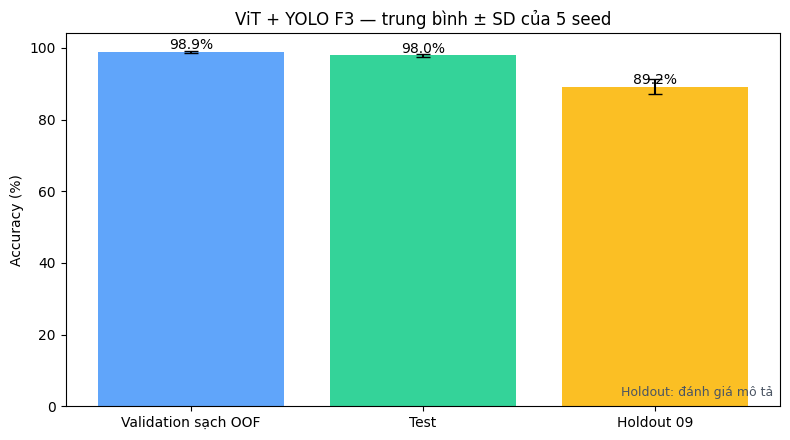

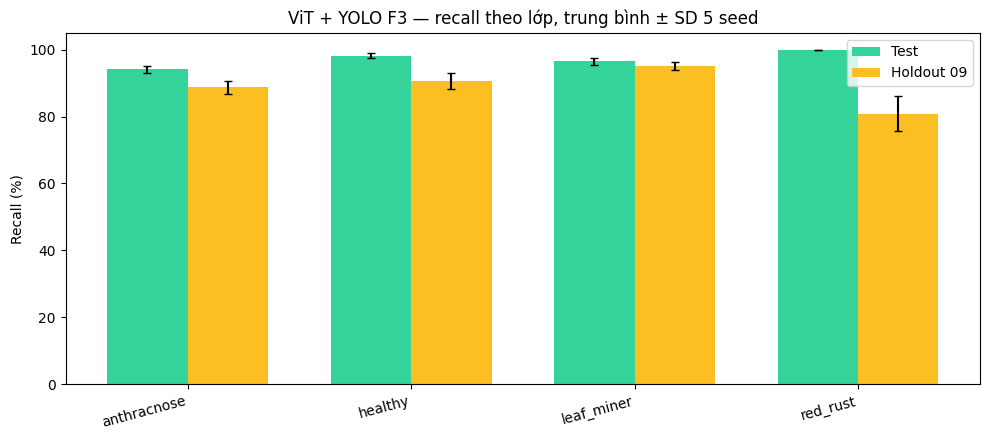

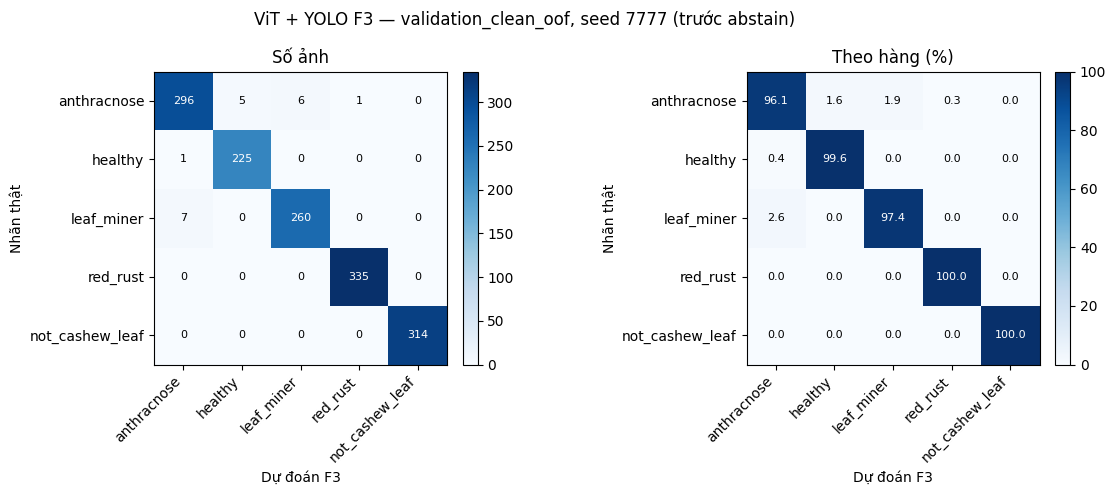

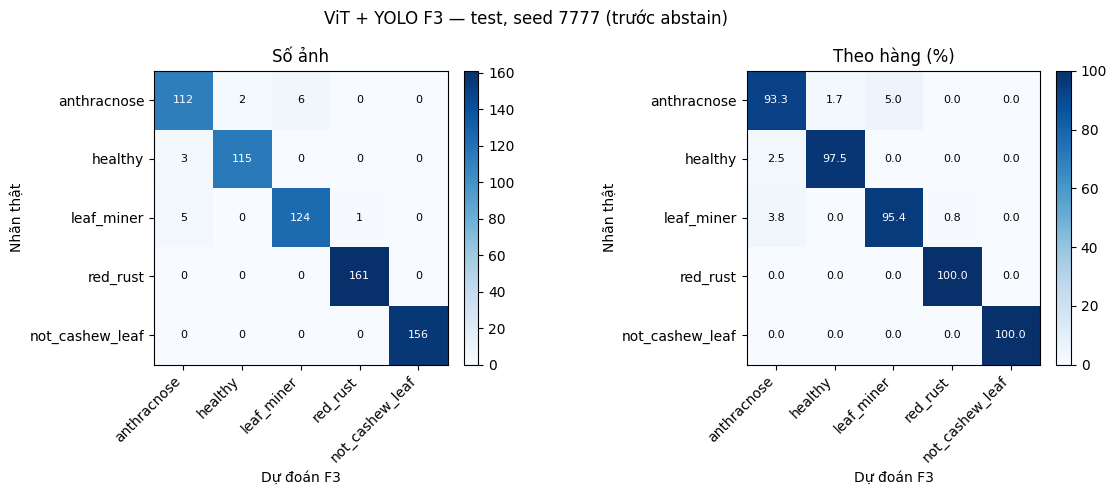

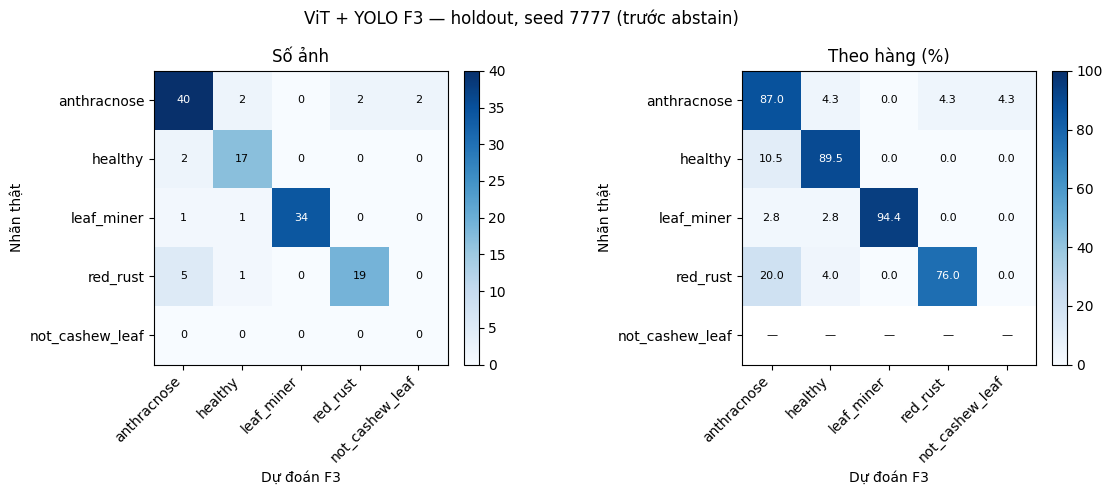

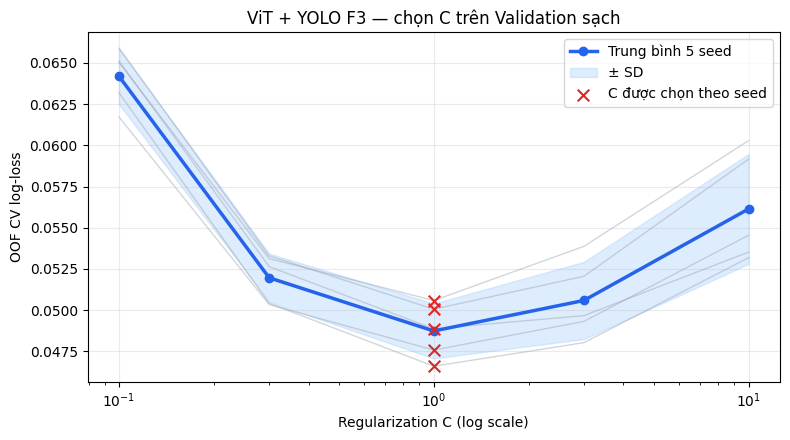

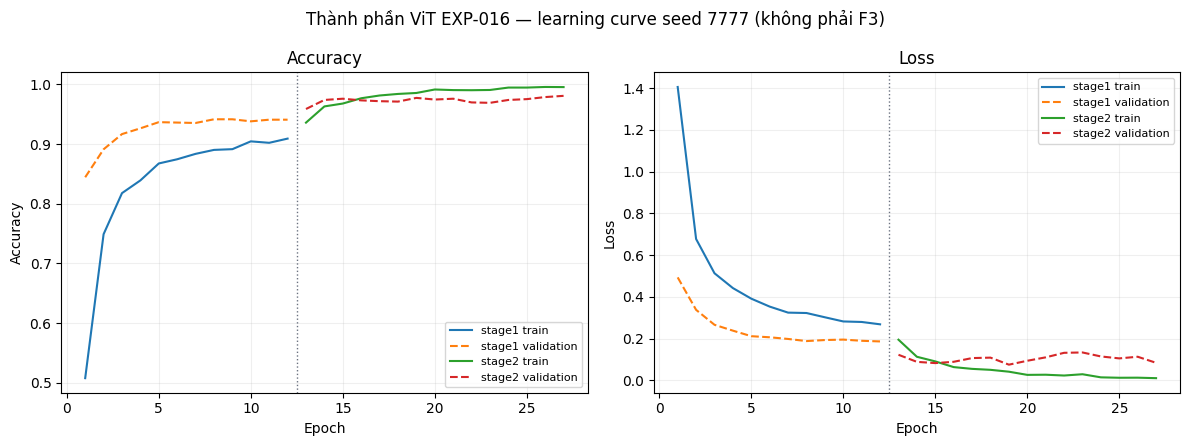

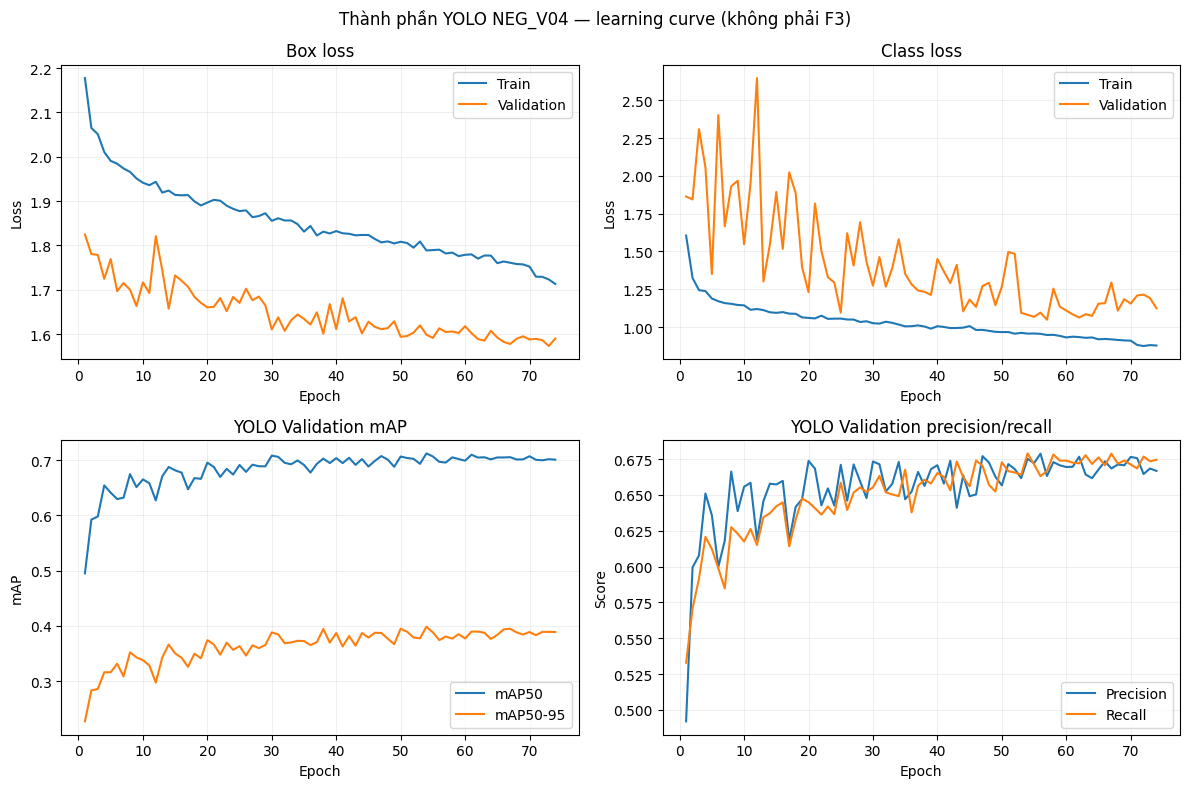

Đã tạo biểu đồ F3 và hai learning curve thành phần tại /content/exp034/EXP-VIT-YOLO-PIPELINE-034/figures/vit_yolo_f3


In [17]:
# 12. Biểu đồ riêng cho mô hình kết hợp ViT + YOLO (rule F3)
# F3 không huấn luyện theo epoch: đồ thị CV theo C là chẩn đoán của stacker.
# Learning curve theo epoch ở cuối ô là lịch sử huấn luyện RIÊNG của ViT và YOLO.
F3_FIG = FIG / 'vit_yolo_f3'
F3_FIG.mkdir(parents=True, exist_ok=True)
F3_RULE = 'F3'
EVAL_ORDER = ['validation_clean_oof', 'test', 'holdout']
f3_results = RESULTS[(RESULTS['rule'] == F3_RULE) & RESULTS['set'].isin(EVAL_ORDER)].copy()
counts = f3_results.groupby('set')['seed'].nunique().reindex(EVAL_ORDER, fill_value=0)
if (counts != len(SEEDS)).any():
    raise RuntimeError(f'Thiếu kết quả F3 của 5 seed: {counts.to_dict()}')

# 12a. Accuracy F3: trung bình ± SD giữa 5 seed trên từng tập.
accuracy_stats = f3_results.groupby('set')['accuracy'].agg(['mean', 'std']).reindex(EVAL_ORDER)
accuracy_stats.to_csv(AGG / 'f3_accuracy_5seeds.csv')
fig, ax = plt.subplots(figsize=(8, 4.5))
means = 100 * accuracy_stats['mean'].to_numpy()
sds = 100 * accuracy_stats['std'].fillna(0).to_numpy()
bars = ax.bar(range(3), means, yerr=sds, capsize=5,
              color=['#60a5fa', '#34d399', '#fbbf24'])
ax.set_xticks(range(3), ['Validation sạch OOF', 'Test', 'Holdout 09'])
ax.set_ylabel('Accuracy (%)')
ax.set_title('ViT + YOLO F3 — trung bình ± SD của 5 seed')
ax.set_ylim(0, min(105, max(100, float(np.max(means + sds)) + 5)))
for bar, value in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, value + 0.7, f'{value:.1f}%', ha='center')
ax.text(0.99, 0.02, 'Holdout: đánh giá mô tả', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=9, color='#4b5563')
fig.tight_layout(); fig.savefig(F3_FIG / 'f3_accuracy_5seeds.png', dpi=180); plt.show()

# 12b. Recall F3 theo 4 lớp có mặt ở cả Test và Holdout; ô không có hỗ trợ không bị coi là 0.
shared_classes = CLASS_NAMES[:4]
recall_cols = [f'recall_{c}' for c in shared_classes]
recall_stats = f3_results[f3_results['set'].isin(['test', 'holdout'])].groupby('set')[recall_cols].agg(['mean', 'std'])
recall_stats.to_csv(AGG / 'f3_recall_test_holdout_5seeds.csv')
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(shared_classes)); width = 0.36
for offset, set_name, color, label in [(-width/2, 'test', '#34d399', 'Test'),
                                       (width/2, 'holdout', '#fbbf24', 'Holdout 09')]:
    values = 100 * recall_stats.loc[set_name, [(c, 'mean') for c in recall_cols]].to_numpy(dtype=float)
    errors = 100 * recall_stats.loc[set_name, [(c, 'std') for c in recall_cols]].fillna(0).to_numpy(dtype=float)
    ax.bar(x + offset, values, width, yerr=errors, capsize=3, color=color, label=label)
ax.set_xticks(x, shared_classes, rotation=15, ha='right')
ax.set_ylabel('Recall (%)')
ax.set_title('ViT + YOLO F3 — recall theo lớp, trung bình ± SD 5 seed')
ax.set_ylim(0, 105); ax.legend(); fig.tight_layout()
fig.savefig(F3_FIG / 'f3_recall_test_holdout_5seeds.png', dpi=180); plt.show()

# 12c. Confusion matrix F3 của seed triển khai: argmax trước cổng uncertain/reject.
for set_name in EVAL_ORDER:
    frame = EVAL_SETS[set_name](PREDICTIONS[
        (PREDICTIONS['rule'] == F3_RULE) & (PREDICTIONS['seed'] == DEPLOYMENT_SEED)])
    if frame.empty:
        raise RuntimeError(f'Không có dự đoán F3 seed {DEPLOYMENT_SEED} trên {set_name}')
    matrix = pd.crosstab(frame['true_label'], frame['pred']).reindex(
        index=CLASS_NAMES, columns=CLASS_NAMES, fill_value=0)
    normalized = 100 * matrix.div(matrix.sum(axis=1).replace(0, np.nan), axis=0)
    matrix.to_csv(AGG / f'f3_confusion_{set_name}_seed{DEPLOYMENT_SEED}.csv')
    normalized.to_csv(AGG / f'f3_confusion_{set_name}_seed{DEPLOYMENT_SEED}_row_pct.csv')
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, values, title, vmax in [
        (axes[0], matrix.to_numpy(dtype=float), 'Số ảnh', max(1, int(matrix.to_numpy().max()))),
        (axes[1], normalized.to_numpy(dtype=float), 'Theo hàng (%)', 100)]:
        masked = np.ma.masked_invalid(values)
        im = ax.imshow(masked, cmap='Blues', vmin=0, vmax=vmax)
        for row in range(len(CLASS_NAMES)):
            for col in range(len(CLASS_NAMES)):
                value = values[row, col]
                text = '—' if not np.isfinite(value) else (f'{value:.1f}' if title.startswith('Theo') else f'{value:.0f}')
                ax.text(col, row, text, ha='center', va='center', fontsize=8,
                        color='white' if np.isfinite(value) and value > vmax * 0.55 else 'black')
        ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha='right')
        ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
        ax.set_xlabel('Dự đoán F3'); ax.set_ylabel('Nhãn thật'); ax.set_title(title)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.suptitle(f'ViT + YOLO F3 — {set_name}, seed {DEPLOYMENT_SEED} (trước abstain)')
    fig.tight_layout(); fig.savefig(F3_FIG / f'f3_confusion_{set_name}_seed{DEPLOYMENT_SEED}.png', dpi=180)
    plt.show()

# 12d. Đường chọn regularization của stacker F3 (CV log-loss, không phải learning curve theo epoch).
cv = pd.DataFrame(CV_TABLE)
cv = cv[cv['rule'] == F3_RULE].copy()
if cv.empty or (cv['C'] <= 0).any():
    raise RuntimeError('Thiếu bảng CV hợp lệ cho stacker F3')
cv_stats = cv.groupby('C')['cv_log_loss'].agg(['mean', 'std']).sort_index()
cv_stats.to_csv(AGG / 'f3_stacker_cv_curve.csv')
fig, ax = plt.subplots(figsize=(8, 4.5))
for seed, frame in cv.groupby('seed'):
    frame = frame.sort_values('C')
    ax.semilogx(frame['C'], frame['cv_log_loss'], color='#9ca3af', alpha=.45, lw=1)
x_cv = cv_stats.index.to_numpy(dtype=float)
y_cv = cv_stats['mean'].to_numpy(dtype=float)
sd_cv = cv_stats['std'].fillna(0).to_numpy(dtype=float)
ax.semilogx(x_cv, y_cv, color='#2563eb', lw=2.5, marker='o', label='Trung bình 5 seed')
ax.fill_between(x_cv, y_cv - sd_cv, y_cv + sd_cv, color='#93c5fd', alpha=.3, label='± SD')
chosen = cv[cv['selected']]
ax.scatter(chosen['C'], chosen['cv_log_loss'], marker='x', color='#dc2626', s=70,
           label='C được chọn theo seed', zorder=3)
ax.set(xlabel='Regularization C (log scale)', ylabel='OOF CV log-loss',
       title='ViT + YOLO F3 — chọn C trên Validation sạch')
ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
fig.savefig(F3_FIG / 'f3_stacker_cv_log_loss.png', dpi=180); plt.show()

# 12e. Learning curve thành phần ViT EXP-016 (seed triển khai), lấy từ ANALYSIS ZIP.
with zipfile.ZipFile(classifier_zip) as archive:
    vit_histories = []
    for stage in ('stage1', 'stage2'):
        member = f'{PREFIX}seed_{DEPLOYMENT_SEED}/{stage}/history.csv'
        if member not in archive.namelist():
            raise FileNotFoundError(f'{classifier_zip.name} thiếu {member}')
        with archive.open(member) as stream:
            history = pd.read_csv(stream)
        needed = {'epoch', 'accuracy', 'val_accuracy', 'loss', 'val_loss'}
        if not needed <= set(history.columns):
            raise RuntimeError(f'{member} thiếu {sorted(needed - set(history.columns))}')
        history['stage'] = stage
        history['global_epoch'] = np.arange(1, len(history)+1) + sum(len(h) for h in vit_histories)
        vit_histories.append(history)
vit_history = pd.concat(vit_histories, ignore_index=True)
vit_history.to_csv(AGG / f'vit016_learning_history_seed{DEPLOYMENT_SEED}.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for stage, history in zip(('stage1', 'stage2'), vit_histories):
    for ax, train_col, val_col, title in [
        (axes[0], 'accuracy', 'val_accuracy', 'Accuracy'),
        (axes[1], 'loss', 'val_loss', 'Loss')]:
        ax.plot(history['global_epoch'], history[train_col], label=f'{stage} train')
        ax.plot(history['global_epoch'], history[val_col], '--', label=f'{stage} validation')
        ax.set(xlabel='Epoch', title=title); ax.grid(alpha=.2)
    if stage == 'stage1':
        boundary = history['global_epoch'].max() + .5
        for ax in axes: ax.axvline(boundary, color='#6b7280', ls=':', lw=1)
axes[0].set_ylabel('Accuracy'); axes[1].set_ylabel('Loss')
for ax in axes: ax.legend(fontsize=8)
fig.suptitle(f'Thành phần ViT EXP-016 — learning curve seed {DEPLOYMENT_SEED} (không phải F3)')
fig.tight_layout(); fig.savefig(F3_FIG / f'vit_component_learning_curve_seed{DEPLOYMENT_SEED}.png', dpi=180)
plt.show()

# 12f. Learning curve thành phần YOLO NEG_V04, lấy từ results.csv của FULL ZIP.
source_yolo_zip = globals().get('yolo_run_zip')
if source_yolo_zip is None or not Path(source_yolo_zip).is_file():
    source_yolo_zip, _ = resolve_input(YOLO_RUN_FULL_ZIP_NAME, folder_id=YOLO_RUN_FOLDER_ID)
with zipfile.ZipFile(source_yolo_zip) as archive:
    members = [name for name in archive.namelist() if name == 'results.csv']
    if len(members) != 1:
        raise FileNotFoundError(f'{Path(source_yolo_zip).name}: thiếu results.csv ở gốc ZIP')
    with archive.open(members[0]) as stream:
        yolo_history = pd.read_csv(stream)
yolo_history.columns = yolo_history.columns.str.strip()
required_yolo = {'epoch', 'train/box_loss', 'val/box_loss', 'train/cls_loss', 'val/cls_loss',
                 'metrics/mAP50(B)', 'metrics/mAP50-95(B)'}
if not required_yolo <= set(yolo_history.columns):
    raise RuntimeError(f'YOLO results.csv thiếu {sorted(required_yolo - set(yolo_history.columns))}')
yolo_history.to_csv(AGG / 'yolo_neg_v04_learning_history.csv', index=False)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, key, title in [(axes[0, 0], 'box_loss', 'Box loss'),
                       (axes[0, 1], 'cls_loss', 'Class loss')]:
    ax.plot(yolo_history['epoch'], yolo_history[f'train/{key}'], label='Train')
    ax.plot(yolo_history['epoch'], yolo_history[f'val/{key}'], label='Validation')
    ax.set(xlabel='Epoch', ylabel='Loss', title=title); ax.grid(alpha=.2); ax.legend()
for col, label in [('metrics/mAP50(B)', 'mAP50'), ('metrics/mAP50-95(B)', 'mAP50-95')]:
    axes[1, 0].plot(yolo_history['epoch'], yolo_history[col], label=label)
axes[1, 0].set(xlabel='Epoch', ylabel='mAP', title='YOLO Validation mAP')
axes[1, 0].grid(alpha=.2); axes[1, 0].legend()
for col, label in [('metrics/precision(B)', 'Precision'), ('metrics/recall(B)', 'Recall')]:
    if col in yolo_history:
        axes[1, 1].plot(yolo_history['epoch'], yolo_history[col], label=label)
axes[1, 1].set(xlabel='Epoch', ylabel='Score', title='YOLO Validation precision/recall')
axes[1, 1].grid(alpha=.2)
if axes[1, 1].lines: axes[1, 1].legend()
fig.suptitle('Thành phần YOLO NEG_V04 — learning curve (không phải F3)')
fig.tight_layout(); fig.savefig(F3_FIG / 'yolo_component_learning_curve.png', dpi=180); plt.show()
print('Đã tạo biểu đồ F3 và hai learning curve thành phần tại', F3_FIG)


In [13]:
# 13. Lá lạ có vết bệnh (NEG_V04 val/test) và ảnh tự chụp: ViT seed triển khai + YOLO + bộ kết hợp
FOREIGN = None
if RUN_FOREIGN_LEAF_EVAL:
    ensure_package('keras-hub==0.32.0', 'keras_hub')
    import tensorflow as tf
    for gpu in tf.config.list_physical_devices('GPU'):
        tf.config.experimental.set_memory_growth(gpu, True)  # để TensorFlow không chiếm hết GPU của YOLO
    from tensorflow import keras
    from tensorflow.keras import layers
    import keras_hub  # đăng ký DeiTBackbone

    # Các lớp tùy biến phải trùng tên đăng ký với EXP-016 để nạp được deployment_model.keras.
    @keras.utils.register_keras_serializable(package='exp029', name='RandomHSVJitter')
    class RandomHSVJitter(layers.Layer):
        def __init__(self, saturation_range=(0.6, 1.4), hue_delta=0.03, grayscale_probability=0.10,
                     value_range=(0.0, 255.0), seed=None, **kwargs):
            super().__init__(**kwargs)
            self.saturation_range = tuple(float(v) for v in saturation_range)
            self.hue_delta = float(hue_delta)
            self.grayscale_probability = float(grayscale_probability)
            self.value_range = tuple(float(v) for v in value_range)
            self.seed = seed
            self.seed_generator = keras.random.SeedGenerator(seed)
        def call(self, inputs, training=False):
            return inputs  # chỉ suy luận: lớp augmentation là identity khi training=False
        def compute_output_shape(self, input_shape):
            return input_shape
        def get_config(self):
            config = super().get_config()
            config.update({'saturation_range': list(self.saturation_range), 'hue_delta': self.hue_delta,
                           'grayscale_probability': self.grayscale_probability,
                           'value_range': list(self.value_range), 'seed': self.seed})
            return config

    @keras.utils.register_keras_serializable(package='deit', name='DeiTImageNetPreprocess')
    class DeiTImageNetPreprocess(layers.Layer):
        MEAN = (0.485, 0.456, 0.406)
        STD = (0.229, 0.224, 0.225)
        def call(self, inputs):
            x = inputs / 255.0
            return (x - tf.constant(self.MEAN, dtype=x.dtype)) / tf.constant(self.STD, dtype=x.dtype)
        def compute_output_shape(self, input_shape):
            return input_shape

    @keras.utils.register_keras_serializable(package='deit', name='TokenSlice')
    class TokenSlice(layers.Layer):
        def __init__(self, index, **kwargs):
            super().__init__(**kwargs)
            self.index = int(index)
        def call(self, inputs):
            return inputs[:, self.index, :]
        def compute_output_shape(self, input_shape):
            return (input_shape[0], input_shape[2])
        def get_config(self):
            config = super().get_config(); config.update({'index': self.index}); return config

    full_zip, _ = resolve_input(CLASSIFIER_FULL_ZIP_NAME, CLASSIFIER_FULL_ZIP_OVERRIDE, folder_id=CLASSIFIER_DRIVE_FOLDER_ID)
    VIT_MODEL_PATH = CACHE_DIR / 'vit016_deployment_model.keras'
    with zipfile.ZipFile(full_zip) as z:
        member = [n for n in z.namelist() if n.endswith('model_package/deployment_model.keras')]
        meta_member = [n for n in z.namelist() if n.endswith('model_package/inference_metadata.json')]
        if len(member) != 1 or len(meta_member) != 1:
            raise RuntimeError(f'{full_zip.name}: cần đúng 1 model và 1 inference_metadata; '
                               f'model={member}, metadata={meta_member}')
        VIT_MODEL_PATH.write_bytes(z.read(member[0]))
        VIT_METADATA = json.loads(z.read(meta_member[0]))
    if VIT_METADATA.get('deployment_seed', DEPLOYMENT_SEED) != DEPLOYMENT_SEED:
        raise RuntimeError(f"deployment_model là seed {VIT_METADATA.get('deployment_seed')}, cần {DEPLOYMENT_SEED}")
    if VIT_METADATA.get('class_names') != CLASS_NAMES:
        raise RuntimeError(f"Thứ tự lớp của deployment_model khác notebook: {VIT_METADATA.get('class_names')}")
    expected_checkpoint = CLASSIFIER_LOCK['selected_checkpoint_sha256'][str(DEPLOYMENT_SEED)]
    if VIT_METADATA.get('source_checkpoint_sha256') != expected_checkpoint:
        raise RuntimeError('ANALYSIS và FULL ZIP của EXP-016 không cùng checkpoint seed triển khai')
    vit = keras.models.load_model(VIT_MODEL_PATH, compile=False)
    INPUTS['vit_deployment_model'] = {'name': member[0], 'sha256': sha256_file(VIT_MODEL_PATH), 'seed': DEPLOYMENT_SEED}

    def vit_probabilities(paths, batch=32, decoder='training_tf'):
        if decoder not in ('training_tf', 'pil_exif'):
            raise ValueError(f"Unknown ViT decoder: {decoder}")
        out = []
        for start in range(0, len(paths), batch):
            arrays = []
            for path in paths[start:start + batch]:
                if decoder == 'training_tf':
                    # Exact EXP-016 make_dataset path used to produce predictions_standard.csv.
                    image = tf.io.decode_image(tf.io.read_file(str(path)), channels=3,
                                               expand_animations=False)
                    image.set_shape([None, None, 3])
                    resized = tf.image.resize(image, [CLASSIFIER_IMG_SIZE, CLASSIFIER_IMG_SIZE],
                                              method='bilinear')
                else:
                    # The original manual adapter; compare only as a diagnostic/fallback.
                    with Image.open(path) as image:
                        rgb = np.asarray(ImageOps.exif_transpose(image).convert('RGB'), dtype=np.float32)
                    resized = tf.image.resize(rgb, [CLASSIFIER_IMG_SIZE, CLASSIFIER_IMG_SIZE],
                                              method='bilinear')
                arrays.append(resized.numpy())
            out.append(vit.predict(np.stack(arrays), verbose=0))
        return np.concatenate(out) if out else np.empty((0, len(CLASS_NAMES)), dtype=float)

    # Keep the parity gate: choose only a decoder that reproduces saved Validation probabilities.
    saved = CLS_PRED[(CLS_PRED['seed'] == DEPLOYMENT_SEED) &
                     (CLS_PRED['split'] == 'validation')].head(LOADER_CHECK_IMAGES)
    if saved.empty:
        raise RuntimeError('Không có Validation predictions để kiểm tra ViT')
    saved_probs = saved[PROB_COLS].to_numpy(dtype=float)
    paths_to_check = saved['path'].tolist()
    recomputed_tf = vit_probabilities(paths_to_check, decoder='training_tf')
    diff_tf = float(np.abs(recomputed_tf - saved_probs).max())
    recomputed_pil = vit_probabilities(paths_to_check, decoder='pil_exif')
    diff_pil = float(np.abs(recomputed_pil - saved_probs).max())
    print(f'ViT parity trên {len(saved)} ảnh: training_tf={diff_tf:.2e}, pil_exif={diff_pil:.2e}; '
          f'ngưỡng={LOADER_MAX_ABS_DIFF:.2e}')
    if diff_tf <= LOADER_MAX_ABS_DIFF:
        VIT_LOADER = 'training_tf'
    elif diff_pil <= LOADER_MAX_ABS_DIFF:
        VIT_LOADER = 'pil_exif'
    else:
        worst = np.abs(recomputed_tf - saved_probs).max(axis=1)
        for index in np.argsort(-worst)[:5]:
            row = saved.iloc[int(index)]
            print('Sai khác Validation:', row['image_id'], 'TF', f'{worst[index]:.3e}',
                  'PIL', f'{np.abs(recomputed_pil[index] - saved_probs[index]).max():.3e}')
        raise RuntimeError('ViT không tái tạo được dự đoán Validation với cả hai decoder; '
                           'kiểm tra cặp ANALYSIS/FULL ZIP và checkpoint seed triển khai')
    INPUTS['vit_deployment_model']['decoder'] = VIT_LOADER
    INPUTS['vit_deployment_model']['parity_max_abs_diff'] = (diff_tf if VIT_LOADER == 'training_tf' else diff_pil)
    print('Decoder được xác thực:', VIT_LOADER)

    foreign_paths = sorted(str(p) for split in ('val', 'test') for p in (YOLO_ROOT / 'images' / split).iterdir()
                           if p.name.lower().startswith('not_cashew_leaf_'))
    groups = {p: f"neg_v04_{Path(p).parent.name}_foreign_diseased_leaf" for p in foreign_paths}
    if FIELD_TEST_DIR:
        field = sorted(str(p) for p in Path(FIELD_TEST_DIR).expanduser().rglob('*') if p.suffix.lower() in IMAGE_SUFFIXES)
        foreign_paths += field
        groups.update({p: 'field_test_dir' for p in field})
    probabilities = vit_probabilities(foreign_paths, decoder=VIT_LOADER)
    foreign_boxes, _ = run_detector(foreign_paths)
    foreign_features = detector_features(foreign_paths, foreign_boxes)
    FOREIGN = foreign_features.copy()
    FOREIGN['group'] = FOREIGN['path'].map(groups)
    for i, name in enumerate(CLASS_NAMES):
        FOREIGN[f'prob_{name}'] = probabilities[:, i]
    for rule, columns in RULES.items():
        if columns is None:
            p = probabilities
        else:
            p = predict_full(STACKERS[(DEPLOYMENT_SEED, rule)]['model'], feature_matrix(FOREIGN, columns))
        FOREIGN[f'{rule}_pred'] = [CLASS_NAMES[i] for i in p.argmax(axis=1)]
        FOREIGN[f'{rule}_confidence'] = p.max(axis=1)
        FOREIGN[f'{rule}_decision'] = [final_decision(pred, conf < UNCERTAIN_THRESHOLD[(DEPLOYMENT_SEED, rule)])
                                       for pred, conf in zip(FOREIGN[f'{rule}_pred'], FOREIGN[f'{rule}_confidence'])]
    FOREIGN['yolo_boxes'] = FOREIGN[[f'n_boxes_{c}' for c in DETECTOR_CLASSES]].sum(axis=1)
    FOREIGN.to_csv(PRED / 'foreign_leaf_predictions.csv', index=False)
    rows = []
    for (group, rule), frame in [((g, r), FOREIGN[FOREIGN['group'] == g]) for g in FOREIGN['group'].unique() for r in RULES]:
        decision = frame[f'{rule}_decision']
        rows.append({'group': group, 'rule': rule, 'images': len(frame),
                     'rejected_not_cashew': int((decision == 'rejected_not_cashew').sum()),
                     'uncertain_retake': int((decision == 'uncertain_retake').sum()),
                     'given_disease_label': int(decision.isin(DISEASE_CLASSES).sum()),
                     'given_healthy_label': int((decision == 'healthy').sum()),
                     'images_with_yolo_box': int((frame['yolo_boxes'] > 0).sum())})
    FOREIGN_SUMMARY = pd.DataFrame(rows)
    FOREIGN_SUMMARY.to_csv(AGG / 'foreign_leaf_summary.csv', index=False)
    print('Lá lạ / ảnh tự chụp — quyết định cuối (seed', DEPLOYMENT_SEED, '):')
    display(FOREIGN_SUMMARY)
else:
    print('Bỏ qua đánh giá lá lạ (RUN_FOREIGN_LEAF_EVAL = False)')


ViT parity trên 24 ảnh: training_tf=8.39e-04, pil_exif=2.95e-02; ngưỡng=2.00e-03
Decoder được xác thực: training_tf
  YOLO: 201/201
Lá lạ / ảnh tự chụp — quyết định cuối (seed 7777 ):


,group,rule,images,rejected_not_cashew,uncertain_retake,given_disease_label,given_healthy_label,images_with_yolo_box
0,neg_v04_test_foreign_diseased_leaf,F0,76,76,0,0,0,22
1,neg_v04_test_foreign_diseased_leaf,F3,76,76,0,0,0,22
2,neg_v04_test_foreign_diseased_leaf,F3a,76,76,0,0,0,22
3,neg_v04_test_foreign_diseased_leaf,F3b,76,61,0,15,0,22
4,neg_v04_val_foreign_diseased_leaf,F0,125,122,3,0,0,8
5,neg_v04_val_foreign_diseased_leaf,F3,125,125,0,0,0,8
6,neg_v04_val_foreign_diseased_leaf,F3a,125,125,0,0,0,8
7,neg_v04_val_foreign_diseased_leaf,F3b,125,123,1,1,0,8


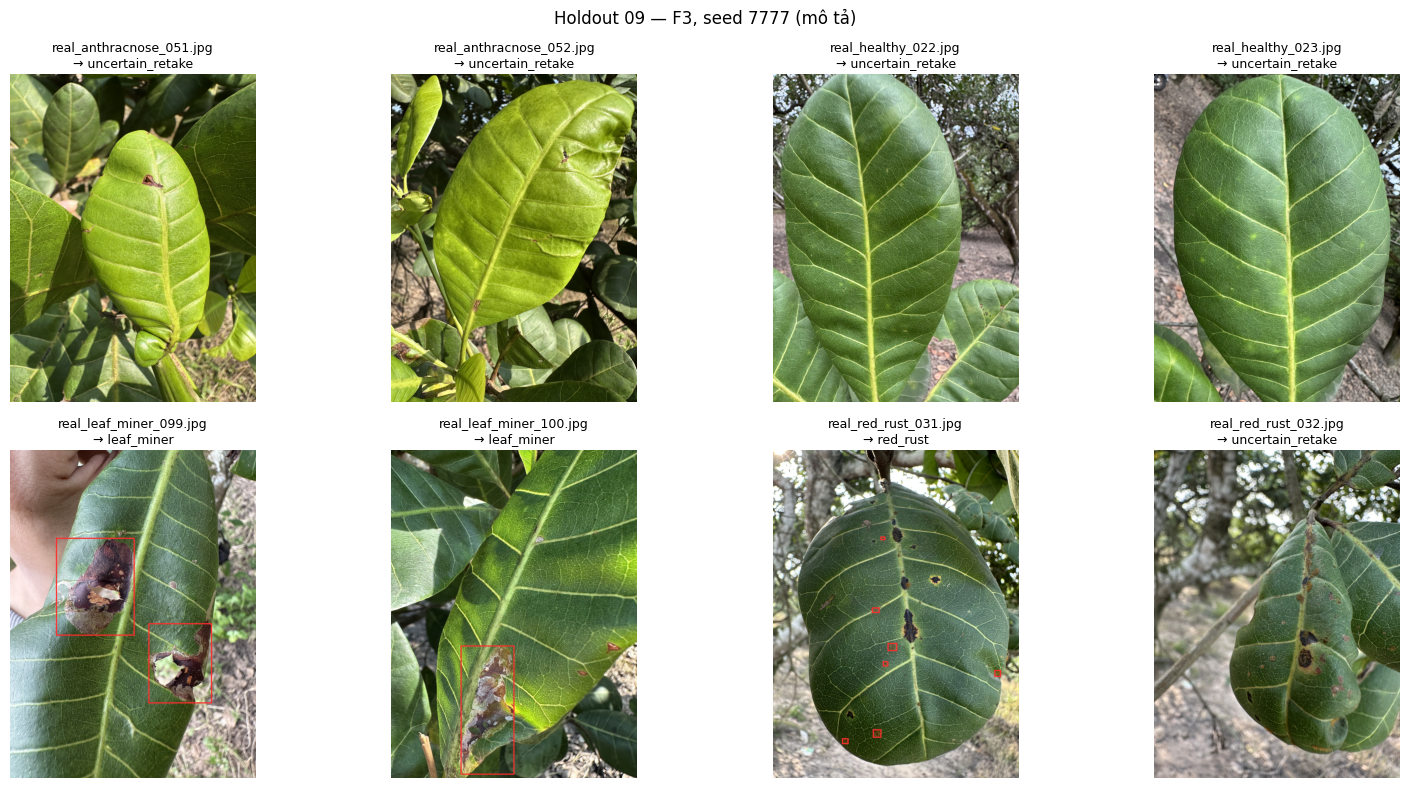

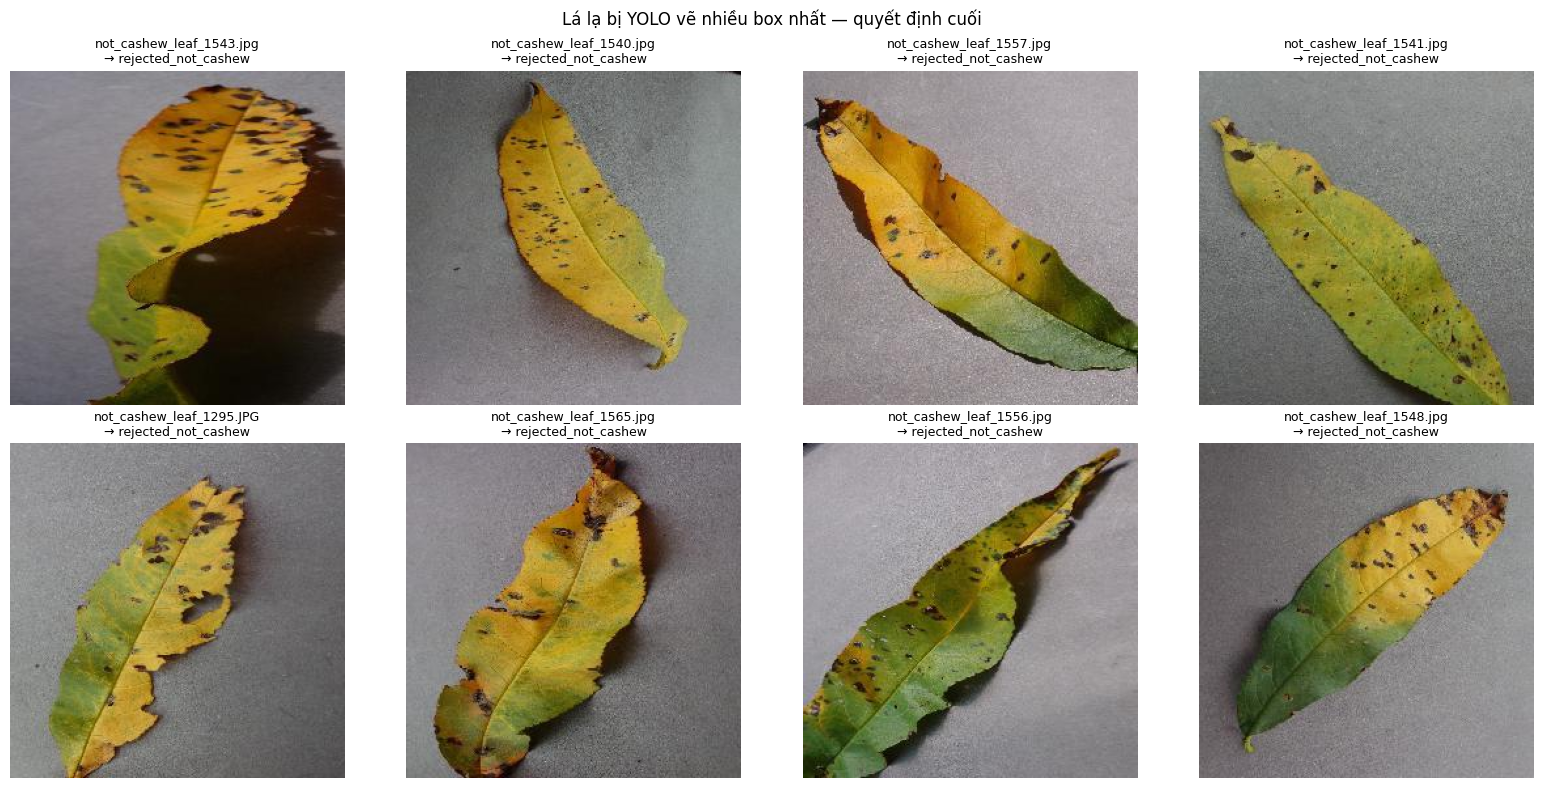

In [14]:
# 14. Ảnh minh họa: nhãn cuối + box YOLO cùng lớp (ẩn box nếu bị từ chối)
def draw_panel(rows, title, destination, max_images=8):
    rows = rows[:max_images]
    if not rows:
        return
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for ax in axes.flat:
        ax.axis('off')
    for ax, (path, decision, boxes) in zip(axes.flat, rows):
        with Image.open(path) as image:
            image = ImageOps.exif_transpose(image).convert('RGB')
        draw = ImageDraw.Draw(image)
        w, h = image.size
        if decision in DISEASE_CLASSES:
            shown = boxes[(boxes['cls'] == decision) & (boxes['conf'] >= BOX_CONF)].nlargest(DISPLAY_MAX_BOXES, 'conf')
            for b in shown.itertuples():
                draw.rectangle((b.x1 * w, b.y1 * h, b.x2 * w, b.y2 * h), outline='#ff2d2d', width=max(2, w // 200))
        ax.imshow(image); ax.set_title(f'{Path(path).name}\n→ {decision}', fontsize=9)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(destination, dpi=150); plt.show()

deploy = PREDICTIONS[(PREDICTIONS['seed'] == DEPLOYMENT_SEED) & (PREDICTIONS['rule'] == DEFAULT_RULE)]
sample = deploy[deploy['split'] == 'holdout'].groupby('true_label').head(2)
draw_panel([(r.path, r.decision, BOXES[BOXES['path'] == r.path]) for r in sample.itertuples()],
           f'Holdout 09 — {DEFAULT_RULE}, seed {DEPLOYMENT_SEED} (mô tả)', FIG / 'qualitative_holdout.png')
if FOREIGN is not None:
    fb = foreign_boxes
    sample = FOREIGN.sort_values('yolo_boxes', ascending=False).head(8)
    draw_panel([(r.path, getattr(r, f'{DEFAULT_RULE}_decision'), fb[fb['path'] == r.path]) for r in sample.itertuples()],
               'Lá lạ bị YOLO vẽ nhiều box nhất — quyết định cuối', FIG / 'qualitative_foreign_leaves.png')


In [15]:
# 15. Gói triển khai (bộ kết hợp seed triển khai + cấu hình + mã suy luận)
deploy_stacker = STACKERS[(DEPLOYMENT_SEED, DEFAULT_RULE)]
joblib.dump({'model': deploy_stacker['model'], 'columns': deploy_stacker['columns'], 'C': deploy_stacker['C'],
             'class_names': CLASS_NAMES, 'detector_classes': DETECTOR_CLASSES},
            BUNDLE / f'stacker_{DEFAULT_RULE}_seed{DEPLOYMENT_SEED}.joblib')
for (seed, rule), item in STACKERS.items():
    joblib.dump({'model': item['model'], 'columns': item['columns'], 'C': item['C']},
                OUT_DIR / 'aggregate' / f'stacker_{rule}_seed{seed}.joblib')
PIPELINE_CONFIG = {
    'experiment_id': EXPERIMENT_ID, 'default_rule': DEFAULT_RULE, 'deployment_seed': DEPLOYMENT_SEED,
    'class_names': CLASS_NAMES, 'detector_classes': DETECTOR_CLASSES, 'classifier_img_size': CLASSIFIER_IMG_SIZE,
    'classifier_decoder': VIT_LOADER,
    'classifier_input': 'RGB float32 0..255, bilinear resize; preprocessing inside the model',
    'yolo': {'weights_sha256': YOLO_WEIGHTS_SHA256, 'imgsz': YOLO_IMGSZ, 'proposal_conf': YOLO_PROPOSAL_CONF,
             'nms_iou': YOLO_NMS_IOU, 'max_det': YOLO_MAX_DET, 'box_conf': BOX_CONF, 'display_max_boxes': DISPLAY_MAX_BOXES},
    'feature_transform': {'prob_*': 'log(clip(p, 1e-6))', 'n_boxes_*': 'log1p', 'area_frac_*': 'union area fraction, 128x128 grid'},
    'uncertain_threshold': UNCERTAIN_THRESHOLD[(DEPLOYMENT_SEED, DEFAULT_RULE)],
    'decision_rule': "argmax == not_cashew_leaf -> reject and hide boxes; confidence < uncertain_threshold -> ask to retake; "
                     "otherwise show label and YOLO boxes of that class (conf >= box_conf, max display boxes)",
    'inputs': INPUTS,
}
save_json(BUNDLE / 'pipeline_config.json', PIPELINE_CONFIG)
PIPELINE_CODE = """# Suy luận EXP-034: ViT EXP-016 (seed 7777) + YOLO26s NEG_V04 + bộ kết hợp F3.
# Cần: deployment_model.keras (EXP-016), best.pt (EXP-Y26S-NEG-V04-001), stacker_F3_seed7777.joblib,
# pipeline_config.json; và định nghĩa RandomHSVJitter, DeiTImageNetPreprocess, TokenSlice như cell 13
# của notebook trước khi nạp mô hình Keras (keras.models.load_model(path, compile=False)).
import json
import joblib
import numpy as np
import tensorflow as tf
from PIL import Image, ImageOps
from ultralytics import YOLO


class CashewPipeline:
    def __init__(self, vit_model, yolo_weights, stacker_path, config_path):
        self.vit = vit_model
        self.yolo = YOLO(yolo_weights)
        bundle = joblib.load(stacker_path)
        self.stacker, self.columns = bundle["model"], bundle["columns"]
        self.cfg = json.load(open(config_path, encoding="utf-8"))
        self.classes = self.cfg["class_names"]

    def _features(self, probs, boxes):
        row = {f"prob_{c}": float(p) for c, p in zip(self.classes, probs)}
        for c in self.cfg["detector_classes"]:
            kept = [b for b in boxes if b["cls"] == c and b["conf"] >= self.cfg["yolo"]["box_conf"]]
            mask = np.zeros((128, 128), dtype=bool)
            for b in kept:
                x1, y1, x2, y2 = b["xyxyn"]
                mask[int(np.floor(y1 * 128)):int(np.ceil(y2 * 128)), int(np.floor(x1 * 128)):int(np.ceil(x2 * 128))] = True
            row[f"max_conf_{c}"] = max([b["conf"] for b in kept], default=0.0)
            row[f"n_boxes_{c}"] = len(kept)
            row[f"area_frac_{c}"] = float(mask.mean()) if kept else 0.0
        values = []
        for col in self.columns:
            v = row[col]
            values.append(np.log(max(v, 1e-6)) if col.startswith("prob_") else np.log1p(v) if col.startswith("n_boxes_") else v)
        return np.asarray(values, dtype=float)[None, :]

    def predict(self, path):
        size = self.cfg["classifier_img_size"]
        decoder = self.cfg["classifier_decoder"]
        if decoder == "training_tf":
            image = tf.io.decode_image(tf.io.read_file(str(path)), channels=3,
                                       expand_animations=False)
            image.set_shape([None, None, 3])
            x = tf.image.resize(image, [size, size], method="bilinear").numpy()[None]
        elif decoder == "pil_exif":
            with Image.open(path) as image:
                rgb = np.asarray(ImageOps.exif_transpose(image).convert("RGB"), dtype=np.float32)
            x = tf.image.resize(rgb, [size, size], method="bilinear").numpy()[None]
        else:
            raise ValueError(f"Unknown classifier decoder: {decoder}")
        probs = self.vit.predict(x, verbose=0)[0]
        y = self.cfg["yolo"]
        result = self.yolo.predict(path, imgsz=y["imgsz"], conf=y["proposal_conf"], iou=y["nms_iou"],
                                   max_det=y["max_det"], verbose=False)[0]
        names = self.cfg["detector_classes"]
        boxes = [{"cls": names[int(c)], "conf": float(s), "xyxyn": [float(v) for v in b]}
                 for c, s, b in zip(result.boxes.cls.tolist(), result.boxes.conf.tolist(), result.boxes.xyxyn.tolist())]
        fused = np.zeros(len(self.classes))
        fused[self.stacker.classes_] = self.stacker.predict_proba(self._features(probs, boxes))[0]
        label = self.classes[int(fused.argmax())]
        confidence = float(fused.max())
        if label == "not_cashew_leaf":
            return {"decision": "rejected_not_cashew", "confidence": confidence, "boxes": []}
        if confidence < self.cfg["uncertain_threshold"]:
            return {"decision": "uncertain_retake", "confidence": confidence, "boxes": []}
        shown = sorted([b for b in boxes if b["cls"] == label and b["conf"] >= y["box_conf"]],
                       key=lambda b: -b["conf"])[:y["display_max_boxes"]]
        return {"decision": label, "confidence": confidence, "probabilities": dict(zip(self.classes, fused.tolist())),
                "boxes": shown}
"""
(BUNDLE / 'cashew_pipeline_034.py').write_text(PIPELINE_CODE, encoding='utf-8')
compile(PIPELINE_CODE, 'cashew_pipeline_034.py', 'exec')
print('Gói triển khai:', sorted(p.name for p in BUNDLE.iterdir()))


Gói triển khai: ['cashew_pipeline_034.py', 'pipeline_config.json', 'stacker_F3_seed7777.joblib']


In [16]:
# 16. Tóm tắt, README và đóng gói ANALYSIS / FULL (+ upload Drive)
def fmt(set_name, rule, column='accuracy'):
    frame = RESULTS[(RESULTS['set'] == set_name) & (RESULTS['rule'] == rule)][column]
    return f'{100 * frame.mean():.2f} ± {100 * frame.std():.2f}'

lines = [f'# {EXPERIMENT_ID}', '',
         f'ViT `{CLASSIFIER_EXPERIMENT_ID}` (5 seed) + YOLO26s `EXP-Y26S-NEG-V04-001` (best.pt SHA-256 `{YOLO_WEIGHTS_SHA256[:16]}…`).',
         f'Bộ kết hợp fit trên Validation sạch của từng seed; Validation báo bằng out-of-fold. Rule mặc định khai báo trước: **{DEFAULT_RULE}**.',
         '', '| Rule | Val sạch (OOF) | Test | Test sạch | Holdout 09 | Holdout n=124 |', '|---|---:|---:|---:|---:|---:|']
for rule in ('F0', 'F3a', 'F3b', 'F3'):
    lines.append(f'| {rule} | ' + ' | '.join(fmt(s, rule) for s in EVAL_SETS) + ' |')
lines += ['', 'Accuracy (%) trung bình ± SD qua 5 seed. Holdout 09 đã được xem trước đây: chỉ là đánh giá mô tả.',
          f'BOX_CONF = {BOX_CONF} kế thừa EXP-033. Rò rỉ: xem `aggregate/leakage_audit.json`.', '',
          '## Bootstrap ghép cặp (điểm %)', '', BOOT.round(2).to_string(index=False)]
if FOREIGN is not None:
    lines += ['', f'## Lá lạ có vết bệnh và ảnh tự chụp (seed {DEPLOYMENT_SEED})', '',
              FOREIGN_SUMMARY.to_string(index=False)]
(OUT_DIR / 'README.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')
CONFIG_KEYS = ['EXPERIMENT_ID', 'CLASSIFIER_EXPERIMENT_ID', 'CLASSIFIER_IMG_SIZE', 'SPLIT13_NAME', 'SPLIT13_SHA256',
               'HOLDOUT_NAME', 'YOLO_DATASET_NAME', 'YOLO_DATASET_SHA256', 'YOLO_WEIGHTS_SHA256', 'YOLO_IMGSZ',
               'YOLO_PROPOSAL_CONF', 'YOLO_NMS_IOU', 'YOLO_MAX_DET', 'BOX_CONF', 'DISPLAY_MAX_BOXES', 'SEEDS',
               'DEPLOYMENT_SEED', 'CLASS_NAMES', 'DETECTOR_CLASSES', 'STACKER_C_GRID', 'CV_FOLDS', 'RANDOM_STATE',
               'UNCERTAIN_COVERAGE', 'DEFAULT_RULE', 'NEAR_DUP_HAMMING', 'RUN_FOREIGN_LEAF_EVAL', 'FIELD_TEST_DIR',
               'BOOTSTRAP_REPS', 'KNOWN_HOLDOUT_DUPLICATES']
save_json(OUT_DIR / 'experiment_config.json', {**{k: globals()[k] for k in CONFIG_KEYS},
                                               'rules': RULES, 'inputs': INPUTS, 'yolo_seconds': YOLO_SECONDS})
save_json(OUT_DIR / 'environment.json', ENVIRONMENT)
print('\n'.join(lines))

heavy = {'.pt', '.keras', '.h5'}
analysis_zip = WORK_ROOT / f'{EXPERIMENT_ID}_ANALYSIS.zip'
full_zip_out = WORK_ROOT / f'{EXPERIMENT_ID}_FULL.zip'
for target, analysis_only in ((analysis_zip, True), (full_zip_out, False)):
    with zipfile.ZipFile(target, 'w', zipfile.ZIP_DEFLATED, compresslevel=6) as z:
        for path in sorted(OUT_DIR.rglob('*')):
            if path.is_file() and not (analysis_only and path.suffix in heavy):
                z.write(path, f'{EXPERIMENT_ID}/{path.relative_to(OUT_DIR).as_posix()}')
        if not analysis_only:
            z.write(YOLO_WEIGHTS, f'{EXPERIMENT_ID}/pipeline_bundle/yolo_neg_v04_best.pt')
            if RUN_FOREIGN_LEAF_EVAL:
                z.write(VIT_MODEL_PATH, f'{EXPERIMENT_ID}/pipeline_bundle/vit016_deployment_model_seed{DEPLOYMENT_SEED}.keras')
    with zipfile.ZipFile(target) as z:
        if z.testzip() is not None:
            raise RuntimeError(f'ZIP lỗi: {target}')
    print('ZIP:', target, f'{target.stat().st_size / 1e6:.1f} MB')

if UPLOAD_TO_DRIVE:
    try:
        from googleapiclient.http import MediaFileUpload
        service = drive_service()
        folder = service.files().create(body={'name': EXPERIMENT_ID, 'mimeType': 'application/vnd.google-apps.folder',
                                              'parents': [DRIVE_RESULTS_FOLDER_ID]},
                                        fields='id,webViewLink', supportsAllDrives=True).execute()
        for archive in (full_zip_out, analysis_zip):
            media = MediaFileUpload(str(archive), mimetype='application/zip', resumable=True, chunksize=32 << 20)
            request = service.files().create(body={'name': archive.name, 'parents': [folder['id']]}, media_body=media,
                                             fields='id,name,size,md5Checksum', supportsAllDrives=True)
            uploaded = None
            while uploaded is None:
                _, uploaded = request.next_chunk(num_retries=5)
            if int(uploaded['size']) != archive.stat().st_size or uploaded['md5Checksum'] != md5_file(archive):
                raise RuntimeError(f'Upload sai: {archive.name}')
        print('Đã upload vào Drive:', folder.get('webViewLink'))
    except Exception as error:
        print('Upload Drive thất bại; ZIP vẫn ở', WORK_ROOT, '|', type(error).__name__, error)


# EXP-VIT-YOLO-PIPELINE-034

ViT `EXP-VIT-DEITSMALL-TRANSFER-LLRD-5SEEDS-016-256px-1192fd08` (5 seed) + YOLO26s `EXP-Y26S-NEG-V04-001` (best.pt SHA-256 `f9dc3fba1347b321…`).
Bộ kết hợp fit trên Validation sạch của từng seed; Validation báo bằng out-of-fold. Rule mặc định khai báo trước: **F3**.

| Rule | Val sạch (OOF) | Test | Test sạch | Holdout 09 | Holdout n=124 |
|---|---:|---:|---:|---:|---:|
| F0 | 97.71 ± 0.36 | 97.14 ± 0.59 | 97.13 ± 0.59 | 85.24 ± 2.14 | 85.48 ± 1.98 |
| F3a | 98.37 ± 0.14 | 96.85 ± 0.70 | 96.84 ± 0.71 | 83.49 ± 2.94 | 83.23 ± 2.98 |
| F3b | 81.72 ± 0.00 | 77.23 ± 0.00 | 77.34 ± 0.00 | 77.78 ± 0.00 | 79.03 ± 0.00 |
| F3 | 98.86 ± 0.18 | 97.99 ± 0.42 | 97.98 ± 0.42 | 89.21 ± 1.99 | 89.03 ± 2.02 |

Accuracy (%) trung bình ± SD qua 5 seed. Holdout 09 đã được xem trước đây: chỉ là đánh giá mô tả.
BOX_CONF = 0.25 kế thừa EXP-033. Rò rỉ: xem `aggregate/leakage_audit.json`.

## Bootstrap ghép cặp (điểm %)

         set comparison   n  delta_points  ci95_low  ci95_hi

Đã upload vào Drive: https://drive.google.com/drive/folders/1zdQdvsB3LmiFdmjRbG-4PAMOLjP21ngq
